# Module 4 — Advanced Models, Comparative Evaluation & Model Integration

**Inputs**
- Module 1: Base splits (`data/processed/*_base.parquet`), `preprocessor.joblib`, `pca_model.joblib`
- Module 2: Augmented splits (`data/augmented/*_augmented.parquet`), `dbscan_model.joblib`, `gmm_model.joblib`
- Module 3: OOF probabilities (`module3/artifacts/oof_predictions/oof_{train,test}_m3.parquet`) and tuned Augmented models (`module3/artifacts/models/*.joblib`), see §1b

**Outputs**: tuned models + stacking meta-learner + `end_to_end_pipeline.joblib` in `artifacts/`, and the leaderboard / significance / SHAP reports in `reports/`.

What this notebook does, in order:
1. **Data ingestion & alignment** — load Base + Augmented splits, assert row/event alignment, define the two feature sets (Module 3's rule).
   **1b. Module 3 baselines** — (i) load Module 3's *delivered* OOF probabilities and models, audit them, and score them under Module 4's metrics; (ii) re-run the same four families on Base **and** Augmented under Module 4's protocol, because the Base-vs-Augmented significance tests need refits on identical splits for both feature sets (Module 3 delivered Augmented OOF only).
2. **Tree ensembles & gradient boosters** — Random Forest, Extra Trees, LightGBM, XGBoost, CatBoost; randomized hyper-parameter search per feature set.
3. **Deep tabular neural net** — PyTorch residual MLP (BatchNorm, Dropout 0.3, GELU, class-weighted CE / focal loss, AdamW + cosine LR).
4. **Two-stage benchmarking** — every model on Base vs Augmented: 5-fold CV + held-out test (Macro F1, Weighted F1, ROC-AUC, log loss).
5. **Integration** — weighted soft voting and a Level-1 stacking meta-learner on OOF probabilities (M3 + M4).
6. **Master leaderboard & statistical significance** — 5×2 CV paired *t*-test and Wilcoxon signed-rank test (Base vs Augmented).
7. **SHAP** — TreeSHAP on the best gradient booster: beeswarm, group importance, dependence plots for fault features.
8. **End-to-end pipeline** — `EarthquakeImpactPipeline` (raw event → M1 → M2 → M4), consistency check, latency benchmark, interactive widget, export.

**Data protocol (fixed by Module 1's stratified split):** *train* (70 %) is used for tuning, OOF generation and significance tests; *val* (15 %) only for neural-net early stopping and config choice; *test* (15 %) is touched once, for final scores.

> The target is extremely imbalanced (test set: 605 green / 43 yellow / 13 orange / **5 red**). Test-set Macro F1 therefore moves a lot when a single red event flips, so the leaderboard reports **5-fold CV Macro F1 (mean ± std)** next to the test metrics, and the significance tests use CV folds, not the test set.

Run with **Kernel → Restart Kernel and Run All Cells** (≈10–20 min on CPU; set `M4_FAST=1` in the environment for a ~2 min smoke run).

## 0. Environment setup
Detects Colab vs local. As in Modules 1 & 2, shared datasets live in the repo-root `data/` folder in both modes (the TODO's `../module1/data/...` local paths are outdated). The repo root is added to `sys.path` so `module4.src` (the neural net and pipeline classes) can be imported — they live in `.py` files so that pickled artifacts load from anywhere.

In [1]:
# Cell 1: Colab / Local Setup with GPU Acceleration Check
import os, sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab. Setting up workspace...")
    from google.colab import drive
    drive.mount('/content/drive')

    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}

    %cd {REPO_PATH}/module4
    !pip install -r ../requirements.txt -q
else:
    print("Running locally.")

DATA_BASE_DIR = "../data/processed"
DATA_AUG_DIR = "../data/augmented"
DATA_RAW_PATH = "../data/raw/usgs_comcat_raw.parquet"
M1_ARTIFACTS_DIR = "../module1/artifacts"
M2_ARTIFACTS_DIR = "../module2/artifacts"
M3_OOF_DIR = "../module3/artifacts/oof_predictions"
ARTIFACTS_DIR = "./artifacts"
M3_FALLBACK_DIR = os.path.join(ARTIFACTS_DIR, "m3_fallback")
REPORTS_DIR = "./reports"
FIG_DIR = os.path.join(REPORTS_DIR, "figures")
for d in (ARTIFACTS_DIR, M3_FALLBACK_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

REPO_ROOT = os.path.abspath("..")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch using device: {device}")

Running locally.


PyTorch using device: cpu


## 0b. Imports & configuration
Every tunable number is here. `FAST_MODE` (env `M4_FAST=1`) shrinks searches/epochs for a quick smoke test — results in fast mode are not the reported ones.

In [2]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import catboost as cb
import lightgbm as lgb
import shap
import sklearn
import xgboost as xgb
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score, log_loss,
                             roc_auc_score, roc_curve, classification_report)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

from module4.src.tabular_nn import TabularResNetClassifier
from module4.src.earthquake_pipeline import EarthquakeImpactPipeline

warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
warnings.filterwarnings("ignore", category=FutureWarning)

# --- General ---
RANDOM_STATE = 42                       # same seed as Modules 1 & 2
SPLITS = ["train", "val", "test"]
CLASSES = ["green", "yellow", "orange", "red"]
ALERT_MAP = {c: i for i, c in enumerate(CLASSES)}
LABELS = list(range(len(CLASSES)))
ALERT_COLORS = ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]

FAST_MODE = os.environ.get("M4_FAST", "0") == "1"
USE_GPU = torch.cuda.is_available()

# --- Cross-validation ---
CV_FOLDS = 5                            # OOF predictions + CV leaderboard scores
SEARCH_FOLDS = 3                        # inner folds for hyper-parameter search
N_SEARCH_ITER = 4 if FAST_MODE else 10 # randomized-search candidates per model per feature set
N_5X2_REPS = 2 if FAST_MODE else 5      # Dietterich's 5x2 CV
ALPHA = 0.05                            # significance level

# --- Neural net ---
MLP_EPOCHS = 30 if FAST_MODE else 200
MLP_PATIENCE = 10 if FAST_MODE else 25

# --- Integration ---
STACK_M3_KEYS = ["lr", "svm", "knn", "lda"]   # Level-0 models from Module 3 (spec)
STACK_M4_KEYS = ["rf", "lgbm", "mlp"]         # Level-0 models from Module 4 (spec)
VOTING_KEYS = ["lgbm", "rf", "svm", "mlp"]    # soft-voting members (spec example)

# --- Pipeline ---
LATENCY_BUDGET_MS = 100.0               # end-to-end predict_single budget (TODO section 7)
DEPLOY_FEATURE_SETS = ["Base", "Augmented"]   # feature sets the deployed model may use; ["Augmented"] = spec-literal

plt.rcParams["figure.dpi"] = 110
# Small tensors: extra torch threads only fight LightGBM/XGBoost/CatBoost's OpenMP pools for cores.
torch.set_num_threads(min(4, os.cpu_count() or 1))

RUN_LOG = os.path.join(ARTIFACTS_DIR, "run_log.txt")
open(RUN_LOG, "w").close()


def log(msg):
    # Print and append to artifacts/run_log.txt (lets you follow a long headless run)
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(RUN_LOG, "a", encoding="utf-8") as fh:
        fh.write(line + "\n")


CV5 = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_SEARCH = StratifiedKFold(SEARCH_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"FAST_MODE={FAST_MODE}  GPU={USE_GPU}  lightgbm {lgb.__version__}  xgboost {xgb.__version__}  "
      f"catboost {cb.__version__}  shap {shap.__version__}  torch {torch.__version__}")

FAST_MODE=False  GPU=False  lightgbm 4.7.0  xgboost 3.4.1  catboost 1.2.10  shap 0.54.1  torch 2.15.0+cpu


## 1. Data ingestion & alignment
Load all six parquet files and check, loudly, that:
- Base and Augmented have identical rows in identical order (`event_id` by position) and the Augmented files contain the Base columns **unchanged**;
- no event appears in two splits;
- the encoded label (`alert_label`) matches `alert`.

In [3]:
base = {s: pd.read_parquet(os.path.join(DATA_BASE_DIR, f"{s}_base.parquet")) for s in SPLITS}
aug = {s: pd.read_parquet(os.path.join(DATA_AUG_DIR, f"{s}_augmented.parquet")) for s in SPLITS}

for s in SPLITS:
    b, a = base[s], aug[s]
    assert len(b) == len(a), f"{s}: row count differs"
    assert (b["event_id"].values == a["event_id"].values).all(), f"{s}: event_id order differs"
    assert b["event_id"].is_unique, f"{s}: duplicate event_id"
    pd.testing.assert_frame_equal(b, a[b.columns], check_dtype=False)   # Base columns untouched by Module 2
    assert (a["alert"].map(ALERT_MAP).values == a["alert_label"].values).all(), f"{s}: alert_label mismatch"

ids = {s: set(aug[s]["event_id"]) for s in SPLITS}
for p, q in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not ids[p] & ids[q], f"leakage: {p} and {q} share events"

y = {s: aug[s]["alert_label"].to_numpy().astype(int) for s in SPLITS}
counts = pd.DataFrame({s: pd.Series(y[s]).value_counts().reindex(LABELS, fill_value=0).values for s in SPLITS},
                      index=CLASSES)
print("Alignment checks passed.")
counts

Alignment checks passed.


,train,val,test
green,2823,605,605
yellow,201,43,43
orange,59,12,13
red,22,5,5


### 1a. Feature sets (Two-Stage protocol, same rule as Module 3)
Module 4 uses **exactly Module 3's feature definitions** (`module3/build_notebook.py`), so every row of the master leaderboard is computed on the same columns:

| Set | Rule | Columns |
|---|---|---|
| **Base** (39) | every column of `*_base.parquet` except the excluded ones | coordinates (`latitude, longitude, depth, lat_rad, lon_rad, x/y/z_ecef`), `mag`, imputed sensors and their robust-scaled copies (`*_scaled`), missingness flags, `magType_*` one-hots, sensor PCA (`pca_sensor_*`) |
| **Augmented** (64) | every column of `*_augmented.parquet` except the excluded ones | Base **+** the 25 Module 2 columns: DBSCAN (`dbscan_cluster`, `is_background_noise`, `dist_to_nearest_fault_km`) and GMM (`gmm_cluster`, `gmm_log_likelihood`, `gmm_prob_0..19`) |

**Excluded** (`EXCLUDE_COLS`): `event_id`, `time`, `place` (metadata), `magType` (raw string, already one-hot encoded), `alert`, `alert_label` (targets) and `mmi` — the secondary target, measured *after* the shaking, which would leak the answer.

So the Base → Augmented step isolates exactly what Module 2's unsupervised fault discovery adds. (Earlier drafts of Module 4 put the sensor PCA on the Augmented side; it was moved to Base to agree with Module 3.)

In [4]:
EXCLUDE_COLS = {"event_id", "time", "alert", "alert_label", "mmi", "place", "magType"}   # identical to Module 3
BASE_FEATURES = [c for c in base["train"].columns if c not in EXCLUDE_COLS]
AUG_FEATURES = [c for c in aug["train"].columns if c not in EXCLUDE_COLS]
FEATURE_SETS = {"Base": BASE_FEATURES, "Augmented": AUG_FEATURES}
M2_COLS = [c for c in AUG_FEATURES if c not in BASE_FEATURES]
assert AUG_FEATURES[:len(BASE_FEATURES)] == BASE_FEATURES, "Augmented must extend Base"

cols = base["train"].columns
COORD_COLS = ["latitude", "longitude", "depth", "lat_rad", "lon_rad", "x_ecef", "y_ecef", "z_ecef"]
SENSOR_RAW_COLS = ["nst", "gap", "dmin", "rms", "horizontalError", "depthError", "magError"]
SCALED_SENSOR_COLS = [c for c in cols if c.endswith("_scaled")]
MISSING_COLS = [c for c in cols if c.startswith("missing_")]
MAGTYPE_COLS = [c for c in cols if c.startswith("magType_")]
PCA_COLS = sorted([c for c in cols if c.startswith("pca_sensor_")], key=lambda c: int(c.rsplit("_", 1)[1]))
GMM_PROB_COLS = sorted([c for c in M2_COLS if c.startswith("gmm_prob_")], key=lambda c: int(c.rsplit("_", 1)[1]))
DBSCAN_COLS = ["dbscan_cluster", "is_background_noise", "dist_to_nearest_fault_km"]
GMM_COLS = ["gmm_cluster", "gmm_log_likelihood"] + GMM_PROB_COLS

FEATURE_GROUPS = {  # used for SHAP group importance
    "Coordinates": COORD_COLS, "Magnitude": ["mag"], "Sensor errors": SENSOR_RAW_COLS + SCALED_SENSOR_COLS,
    "Missingness flags": MISSING_COLS, "magType": MAGTYPE_COLS, "Sensor PCA": PCA_COLS,
    "DBSCAN fault": DBSCAN_COLS, "GMM fault posteriors": GMM_COLS,
}
grouped = [c for g in FEATURE_GROUPS.values() for c in g]
assert sorted(grouped) == sorted(AUG_FEATURES), f"ungrouped/unknown features: {set(AUG_FEATURES) ^ set(grouped)}"
assert sorted(M2_COLS) == sorted(DBSCAN_COLS + GMM_COLS), "unexpected Module 2 columns"

LEAKY = {"alert", "alert_label", "mmi", "event_id"}
assert not LEAKY & set(AUG_FEATURES), "target leakage into features"
assert not aug["train"][AUG_FEATURES].isna().any().any(), "NaNs in features"

X = {(fs, s): aug[s][feats].astype(float) for fs, feats in FEATURE_SETS.items() for s in SPLITS}
print(f"Base features: {len(BASE_FEATURES)} | Augmented features: {len(AUG_FEATURES)} (+{len(M2_COLS)} from Module 2)")
print("Excluded columns:", sorted(EXCLUDE_COLS & set(aug["train"].columns)))

Base features: 39 | Augmented features: 64 (+25 from Module 2)
Excluded columns: ['alert', 'alert_label', 'event_id', 'magType', 'mmi', 'place', 'time']


### Shared helpers
- `evaluate` — the four leaderboard metrics. `macro` averaging so orange/red count as much as green; ROC-AUC is one-vs-rest macro.
- `fit_model` — one place that knows model quirks: XGBoost has no `class_weight`, so it gets balanced `sample_weight`; the neural net gets the val split for early stopping when asked.
- `run_model` — the standard protocol for any (model, feature set): 5-fold OOF on train (→ CV score + stacking features), refit on all of train, predict val/test, measure single-row latency.

In [5]:
def evaluate(y_true, proba):
    proba = np.clip(np.asarray(proba, dtype=float), 1e-15, 1.0)
    proba = proba / proba.sum(axis=1, keepdims=True)
    pred = proba.argmax(axis=1)
    return {
        "macro_f1": f1_score(y_true, pred, average="macro", labels=LABELS, zero_division=0),
        "weighted_f1": f1_score(y_true, pred, average="weighted", labels=LABELS, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=LABELS),
        "log_loss": log_loss(y_true, proba, labels=LABELS),
    }


def macro_f1(y_true, proba):
    return f1_score(y_true, np.asarray(proba).argmax(axis=1), average="macro", labels=LABELS, zero_division=0)


def fit_model(key, est, X_fit, y_fit, eval_set=None):
    kw = {}
    if MODEL_SPECS[key].get("sample_weight"):
        kw["sample_weight"] = compute_sample_weight("balanced", y_fit)
    if key == "mlp" and eval_set is not None:
        kw["eval_set"] = eval_set
    return est.fit(X_fit, y_fit, **kw)


def single_row_latency_ms(model, X_test, n=40):
    rows = [X_test.iloc[[i]] for i in range(min(n, len(X_test)))]
    model.predict_proba(rows[0])                       # warm-up
    times = []
    for r in rows:
        t0 = time.perf_counter()
        model.predict_proba(r)
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


RESULTS = {}   # (key, feature_set) -> dict(oof, val_proba, test_proba, cv_scores, test metrics, model, ...)


def run_model(key, fs, est):
    Xtr, Xva, Xte = X[(fs, "train")], X[(fs, "val")], X[(fs, "test")]
    ytr = y["train"]
    t0 = time.perf_counter()
    oof = np.zeros((len(Xtr), len(CLASSES)))
    fold_scores = []
    for tr_idx, va_idx in CV5.split(Xtr, ytr):
        m = fit_model(key, clone(est), Xtr.iloc[tr_idx], ytr[tr_idx])
        oof[va_idx] = m.predict_proba(Xtr.iloc[va_idx])
        fold_scores.append(macro_f1(ytr[va_idx], oof[va_idx]))
    final = fit_model(key, clone(est), Xtr, ytr, eval_set=(Xva, y["val"]))
    # Inference is single-row in production: a thread pool per call (n_jobs=-1) costs more than it saves.
    if MODEL_SPECS[key].get("threads") == "n_jobs":
        final.set_params(n_jobs=1)
    p_val, p_test = final.predict_proba(Xva), final.predict_proba(Xte)
    for p in (oof, p_val, p_test):
        assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5), f"{key}/{fs}: probabilities do not sum to 1"
    res = {"key": key, "fs": fs, "model": final, "oof": oof, "val_proba": p_val, "test_proba": p_test,
           "cv_scores": np.array(fold_scores), **evaluate(y["test"], p_test),
           "val_macro_f1": macro_f1(y["val"], p_val), "latency_ms": single_row_latency_ms(final, Xte),
           "train_time_s": time.perf_counter() - t0}
    RESULTS[(key, fs)] = res
    log(f"{MODEL_SPECS[key]['name']:<26s} [{fs:9s}]  CV macro-F1 {res['cv_scores'].mean():.3f} ± {res['cv_scores'].std():.3f} | "
          f"test macro-F1 {res['macro_f1']:.3f}  AUC {res['roc_auc']:.3f}  logloss {res['log_loss']:.3f}  "
          f"({res['train_time_s']:.0f}s)")
    return res


def tune(key, fs):
    spec = MODEL_SPECS[key]
    est = spec["make"]()
    if not spec.get("grid"):
        return est, {}
    fit_kw = {"sample_weight": compute_sample_weight("balanced", y["train"])} if spec.get("sample_weight") else {}
    if spec.get("search") == "grid":
        search = GridSearchCV(est, spec["grid"], scoring="f1_macro", cv=CV_SEARCH, n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, spec["grid"], n_iter=N_SEARCH_ITER, scoring="f1_macro", cv=CV_SEARCH,
                                    n_jobs=1 if (USE_GPU and spec.get("gpu")) else -1, random_state=RANDOM_STATE)
    search.fit(X[(fs, "train")], y["train"], **fit_kw)
    best = clone(search.best_estimator_)
    if spec.get("threads"):                      # single-threaded during parallel search, all cores afterwards
        best.set_params(**{spec["threads"]: -1})
    return best, {"params": search.best_params_, "search_cv_macro_f1": search.best_score_}


BEST_EST, TUNING = {}, {}

## 1b. Module 3 baselines
Module 4 needs two things from Module 3: baseline scores for the master leaderboard, and out-of-fold (OOF) probabilities for the stacker.

**(i) Module 3 as delivered.** `module3/artifacts/oof_predictions/oof_{train,test}_m3.parquet` hold the OOF (train) and test probabilities of Module 3's tuned Augmented Logistic Regression, LDA, *k*-NN and SVC. Module 3 used the same splitter as Module 4 (`StratifiedKFold(5, shuffle=True, random_state=42)`), so these OOF columns can be stacked with Module 4's without leakage, and their CV scores can be computed per fold here. These rows appear in the leaderboard as *"Module 3 delivered"* and are the Module 3 Level-0 inputs of the stacker in §5. The saved models in `module3/artifacts/models/` are loaded when possible (for latency and inference); one that cannot be un-pickled outside Module 3's notebook is reported, not fixed here.

**(ii) The same families re-run under Module 4's protocol.** Module 3 delivered Augmented OOF only, but the Base-vs-Augmented significance tests (§6b) must refit each model on *identical* halves of train for both feature sets. So the four families are tuned again here, separately per feature set, with grids that contain Module 3's chosen configurations:

| key | model | 3-fold grid (Macro F1) |
|---|---|---|
| `lr` | Logistic Regression (L2, `lbfgs`), `class_weight='balanced'` | `C` ∈ {0.01, 0.1, 1, 10} — L1 is left out because its `saga` solver needed ~100 s per fit on the Augmented set; Module 3's delivered L1 model is scored in (i) |
| `lda` | LDA, `lsqr` + Ledoit-Wolf shrinkage (handles the collinear coordinate columns) | — |
| `knn` | *k*-NN | *k* ∈ {3, 7, 15} × weights ∈ {uniform, distance} |
| `svm` | SVC, `class_weight='balanced'`, Platt probabilities | kernel ∈ {RBF, poly degree 2} × `C` ∈ {1, 10} |

Scale-sensitive models standardise inside an sklearn `Pipeline`, so the scaler is re-fit in every fold. If Module 3's files are missing, the re-run models also stand in as the stacker's Module 3 inputs, and their OOF is exported in Module 3's schema to `artifacts/m3_fallback/` (never into `module3/`).

In [6]:
MODEL_SPECS = {
    # ---------------- Module 3 families ----------------
    "lr": {"name": "Logistic Regression", "family": "Linear (M3)", "module": "M3", "search": "grid",
           "make": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, l1_ratio=0.0, solver="lbfgs",
                                                                              class_weight="balanced", max_iter=5000)),
           # L2 only: L1 needs the saga solver, which took ~100 s per fit on the Augmented set (the 20 GMM posteriors
           # sum to 1, so they are collinear) and would dominate the 5x2 tests. Module 3's delivered L1 model is still
           # scored in the leaderboard.
           "grid": {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]}},
    "lda": {"name": "LDA", "family": "Probabilistic (M3)", "module": "M3",
            "make": lambda: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))},
    "knn": {"name": "k-NN", "family": "Instance (M3)", "module": "M3", "search": "grid",
            "make": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
            "grid": {"kneighborsclassifier__n_neighbors": [3, 7, 15],
                     "kneighborsclassifier__weights": ["uniform", "distance"]}},
    "svm": {"name": "SVC", "family": "Kernel (M3)", "module": "M3", "search": "grid",
            "make": lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", degree=2, probability=True,
                                                                class_weight="balanced", random_state=RANDOM_STATE)),
            "grid": {"svc__kernel": ["rbf", "poly"], "svc__C": [1.0, 10.0]}},
}


def config_label(key, fs):
    # Human-readable tuned configuration of a re-run Module 3 model, e.g. "k-NN (k=3, distance)"
    p = {k.split("__")[-1]: v for k, v in TUNING.get((key, fs), {}).get("params", {}).items()}
    if key == "lr":
        return f"Logistic Regression ({'L1' if p.get('l1_ratio') == 1.0 else 'L2'}, C={p.get('C')})"
    if key == "knn":
        return f"k-NN (k={p.get('n_neighbors')}, {p.get('weights')})"
    if key == "svm":
        return f"SVC ({'poly deg=2' if p.get('kernel') == 'poly' else 'RBF'}, C={p.get('C')})"
    if key == "lda":
        return "LDA (lsqr, shrinkage=auto)"
    return MODEL_SPECS[key]["name"]


M3_KEYS = ["lr", "lda", "knn", "svm"]
for key in M3_KEYS:
    for fs in FEATURE_SETS:
        BEST_EST[(key, fs)], TUNING[(key, fs)] = tune(key, fs)
        run_model(key, fs, BEST_EST[(key, fs)])
        log(f"   -> re-run config [{fs}]: {config_label(key, fs)}")

[13:22:48] Logistic Regression        [Base     ]  CV macro-F1 0.466 ± 0.054 | test macro-F1 0.532  AUC 0.954  logloss 0.254  (4s)


[13:22:48]    -> re-run config [Base]: Logistic Regression (L2, C=10.0)


[13:23:00] Logistic Regression        [Augmented]  CV macro-F1 0.448 ± 0.062 | test macro-F1 0.460  AUC 0.941  logloss 0.288  (9s)


[13:23:00]    -> re-run config [Augmented]: Logistic Regression (L2, C=10.0)


[13:23:00] LDA                        [Base     ]  CV macro-F1 0.471 ± 0.042 | test macro-F1 0.515  AUC 0.949  logloss 0.592  (0s)


[13:23:00]    -> re-run config [Base]: LDA (lsqr, shrinkage=auto)


... (6 outputs left out)

[13:23:12] SVC                        [Base     ]  CV macro-F1 0.437 ± 0.020 | test macro-F1 0.467  AUC 0.945  logloss 0.157  (8s)


[13:23:12]    -> re-run config [Base]: SVC (poly deg=2, C=1.0)


[13:23:18] SVC                        [Augmented]  CV macro-F1 0.438 ± 0.024 | test macro-F1 0.460  AUC 0.941  logloss 0.170  (3s)


[13:23:18]    -> re-run config [Augmented]: SVC (poly deg=2, C=10.0)


### 1b-(i). Load and audit Module 3's delivered outputs
Checks: rows align with our splits by `event_id`, labels match, probabilities sum to 1. Scores are recomputed with Module 4's `evaluate` on the shared folds, so they are directly comparable with every other leaderboard row. Where a delivered model loads, we also confirm it reproduces Module 3's delivered test probabilities.

In [7]:
M3_MODEL_FILES = {"lr": "logistic_regression_aug.joblib", "lda": "lda_aug.joblib",
                  "knn": "knn_aug.joblib", "svm": "svm_rbf_aug.joblib"}
M3_MODELS_DIR = os.path.join(os.path.dirname(M3_OOF_DIR), "models")
M3_OOF_PATHS = {s: os.path.join(M3_OOF_DIR, f"oof_{s}_m3.parquet") for s in ["train", "test"]}
M3_AVAILABLE = all(os.path.exists(p) for p in M3_OOF_PATHS.values())
M3_DELIVERED = {}   # key -> dict(oof, test_proba, cv_scores, metrics, model or None, label, note)


def describe_m3_model(key, model):
    est = model.steps[-1][1] if hasattr(model, "steps") else model
    p = est.get_params()
    if key == "lr":
        l1 = p.get("l1_ratio")
        pen = "L1" if (l1 == 1 or p.get("penalty") == "l1") else ("L2" if l1 in (0, None) else f"elastic-net {l1}")
        return f"Logistic Regression ({pen}, C={p.get('C')})"
    if key == "lda":
        return f"LDA ({p.get('solver')}, shrinkage={p.get('shrinkage')})"
    if key == "svm":
        kern = p.get("kernel")
        return f"SVC ({kern}{' deg=' + str(p.get('degree')) if kern == 'poly' else ''}, C={p.get('C')})"
    if key == "knn":
        return f"k-NN (k={p.get('n_neighbors', p.get('k'))}, {p.get('weights')})"
    return key


if M3_AVAILABLE:
    frames = {}
    for s, path in M3_OOF_PATHS.items():
        df = pd.read_parquet(path)
        assert set(df["event_id"]) == set(aug[s]["event_id"]), f"Module 3 {s}: event set differs from our split"
        df = df.set_index("event_id").loc[aug[s]["event_id"]]
        assert (df["true_label"].to_numpy() == y[s]).all(), f"Module 3 {s}: labels do not match"
        frames[s] = df
    audit = []
    for key in M3_KEYS:
        cols_k = [f"{key}_prob_{c}" for c in CLASSES]
        oof, test_p = frames["train"][cols_k].to_numpy(), frames["test"][cols_k].to_numpy()
        assert np.allclose(oof.sum(1), 1, atol=1e-4) and np.allclose(test_p.sum(1), 1, atol=1e-4), f"{key}: rows do not sum to 1"
        cv_scores = np.array([macro_f1(y["train"][va], oof[va]) for _, va in CV5.split(X[("Augmented", "train")], y["train"])])
        model, note, label, latency, repro = None, "", f"{MODEL_SPECS[key]['name']} (Module 3)", np.nan, np.nan
        try:
            with warnings.catch_warnings(record=True) as caught:      # sklearn version-mismatch warnings
                warnings.simplefilter("always")
                model = joblib.load(os.path.join(M3_MODELS_DIR, M3_MODEL_FILES[key]))
            versions = sorted({str(getattr(w.message, "original_sklearn_version", "")) for w in caught} - {""})
            if versions:
                note = f"pickled with scikit-learn {', '.join(versions)} (running {sklearn.__version__})"
            names = list(getattr(model, "feature_names_in_", AUG_FEATURES))
            if names != AUG_FEATURES:
                note, model = "saved model expects different feature columns; not used for inference", None
            else:
                label = describe_m3_model(key, model)
                repro = float(np.abs(model.predict_proba(X[("Augmented", "test")]) - test_p).max())
                latency = single_row_latency_ms(model, X[("Augmented", "test")])
        except Exception as exc:          # e.g. a class defined inside Module 3's notebook
            note = f"saved model not loadable outside Module 3's notebook ({type(exc).__name__}: {str(exc)[:80]})"
            model = None
        M3_DELIVERED[key] = {"oof": oof, "test_proba": test_p, "cv_scores": cv_scores, "model": model,
                             "label": label, "note": note, "latency_ms": latency, **evaluate(y["test"], test_p)}
        audit.append({"key": key, "model": label, "OOF CV macro-F1": cv_scores.mean(), "test macro-F1": M3_DELIVERED[key]["macro_f1"],
                      "test ROC-AUC": M3_DELIVERED[key]["roc_auc"], "model reproduces test probs (max |Δ|)": repro,
                      "note": note or "ok"})
    M3_SOURCE = "Module 3 delivered (module3/artifacts/oof_predictions)"
    log(f"Module 3 delivered outputs loaded and audited ({len(M3_DELIVERED)} models)")
    display(pd.DataFrame(audit).round(4))
else:
    M3_SOURCE = "Module 4 re-run of the Module 3 families (artifacts/m3_fallback)"
    warnings.warn("Module 3 OOF files not found - the re-run models stand in for Module 3 in stacking.")
print("Module 3 source for stacking:", M3_SOURCE)

[13:23:18] Module 3 delivered outputs loaded and audited (4 models)


,key,model,OOF CV macro-F1,test macro-F1,test ROC-AUC,model reproduces test probs (max |Δ|),note
0,lr,"Logistic Regression (L1, C=0.1)",0.4555,0.4500,0.9396,0.0,pickled with scikit-learn 1.9.0 (running 1.9.1)
1,lda,"LDA (eigen, shrinkage=auto)",0.4589,0.4724,0.9492,0.0,pickled with scikit-learn 1.6.1 (running 1.9.1)
2,knn,k-NN (Module 3),0.4758,0.4461,0.8190,NaN,saved model not loadable outside Module 3's no...
3,svm,"SVC (poly deg=3, C=1.0)",0.4430,0.4693,0.9601,0.0,ok


Module 3 source for stacking: Module 3 delivered (module3/artifacts/oof_predictions)


In [8]:
# Export the re-run OOF in Module 3's schema only when Module 3's own files are missing
def m3_oof_frame(split):
    # Module 3 OOF schema (module3/TODO.md section 6.1); Augmented models, as the spec asks
    df = pd.DataFrame({"event_id": aug[split]["event_id"].values})
    for key in ["lr", "svm", "knn", "lda"]:
        r = RESULTS[(key, "Augmented")]
        proba = r["oof"] if split == "train" else r["test_proba"]
        for j, c in enumerate(CLASSES):
            df[f"{key}_prob_{c}"] = proba[:, j]
    df["true_label"] = y[split].astype("int32")
    return df

if not M3_AVAILABLE:
    for split in ["train", "test"]:
        path = os.path.join(M3_FALLBACK_DIR, f"oof_{split}_m3.parquet")
        m3_oof_frame(split).to_parquet(path, index=False)
        print("saved", path)
else:
    print("Module 3's own OOF files are present; no fallback export needed.")

Module 3's own OOF files are present; no fallback export needed.


## 2. Advanced tree ensembles & gradient boosters
| key | model | imbalance handling | searched hyper-parameters |
|---|---|---|---|
| `rf` | Random Forest (400 trees) | `class_weight='balanced_subsample'` (cost-sensitive per bootstrap) | depth, leaf size, `max_features` |
| `et` | Extra Trees (400 trees) | `balanced_subsample` | depth, leaf size, `max_features` |
| `lgbm` | LightGBM | `class_weight='balanced'` | learning rate, leaves, depth, min child samples, L1/L2, row/feature subsampling, #trees |
| `xgb` | XGBoost (`hist`) | balanced `sample_weight` | learning rate, depth, min child weight, L1/L2, row/feature subsampling, #trees |
| `cat` | CatBoost | `auto_class_weights='Balanced'` | learning rate, depth, L2 leaf reg, feature subsampling |

Each model is tuned **separately on Base and on Augmented** (`RandomizedSearchCV`, 3 stratified folds of train, Macro F1), so neither feature set is handicapped by hyper-parameters chosen for the other. GPU: XGBoost uses `device='cuda'` and CatBoost `task_type='GPU'` when a GPU is present; LightGBM's pip wheel is CPU-only, which is fine at this data size (~3k rows).

In [9]:
XGB_DEVICE = "cuda" if USE_GPU else "cpu"
CAT_TASK = "GPU" if USE_GPU else "CPU"

MODEL_SPECS.update({
    "rf": {"name": "Random Forest", "family": "Tree Ensemble (M4)", "module": "M4", "threads": "n_jobs",
           "make": lambda: RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", n_jobs=1,
                                                  random_state=RANDOM_STATE),
           "grid": {"max_depth": [None, 8, 12, 16], "min_samples_leaf": [1, 2, 4, 8],
                    "max_features": ["sqrt", 0.3, 0.5]}},
    "et": {"name": "Extra Trees", "family": "Tree Ensemble (M4)", "module": "M4", "threads": "n_jobs",
           "make": lambda: ExtraTreesClassifier(n_estimators=400, class_weight="balanced_subsample", n_jobs=1,
                                                random_state=RANDOM_STATE),
           "grid": {"max_depth": [None, 8, 12, 16], "min_samples_leaf": [1, 2, 4, 8],
                    "max_features": ["sqrt", 0.3, 0.5]}},
    "lgbm": {"name": "LightGBM", "family": "Gradient Boost (M4)", "module": "M4", "threads": "n_jobs",
             "make": lambda: lgb.LGBMClassifier(objective="multiclass", class_weight="balanced", n_estimators=300,
                                                subsample_freq=1, n_jobs=1, verbosity=-1, random_state=RANDOM_STATE),
             "grid": {"learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31], "max_depth": [-1, 4, 6],
                      "min_child_samples": [5, 10, 20], "reg_alpha": [0.0, 0.1, 1.0], "reg_lambda": [0.0, 1.0, 5.0],
                      "subsample": [0.7, 0.9, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "n_estimators": [200, 400]}},
    "xgb": {"name": "XGBoost", "family": "Gradient Boost (M4)", "module": "M4", "threads": "n_jobs",
            "sample_weight": True, "gpu": USE_GPU,
            "make": lambda: xgb.XGBClassifier(objective="multi:softprob", tree_method="hist", device=XGB_DEVICE,
                                              n_estimators=300, eval_metric="mlogloss", n_jobs=1,
                                              random_state=RANDOM_STATE),
            "grid": {"learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6], "min_child_weight": [1, 3, 5],
                     "reg_alpha": [0.0, 0.1, 1.0], "reg_lambda": [1.0, 5.0], "subsample": [0.7, 0.9, 1.0],
                     "colsample_bytree": [0.6, 0.8, 1.0], "n_estimators": [200, 400]}},
    "cat": {"name": "CatBoost", "family": "Gradient Boost (M4)", "module": "M4", "threads": "thread_count",
            "gpu": USE_GPU,
            "make": lambda: cb.CatBoostClassifier(loss_function="MultiClass", auto_class_weights="Balanced",
                                                  iterations=400, task_type=CAT_TASK, thread_count=1, verbose=0,
                                                  allow_writing_files=False, random_seed=RANDOM_STATE),
            "grid": {"learning_rate": [0.03, 0.06, 0.1], "depth": [4, 5, 6], "l2_leaf_reg": [1, 3, 10],
                     **({} if USE_GPU else {"rsm": [0.6, 0.8, 1.0]})}},
})

TREE_KEYS = ["rf", "et", "lgbm", "xgb", "cat"]
tuning_rows = []
for key in TREE_KEYS:
    for fs in FEATURE_SETS:
        t0 = time.perf_counter()
        BEST_EST[(key, fs)], TUNING[(key, fs)] = tune(key, fs)
        tuning_rows.append({"model": MODEL_SPECS[key]["name"], "feature_set": fs,
                            "search CV macro-F1": round(TUNING[(key, fs)]["search_cv_macro_f1"], 4),
                            "best params": TUNING[(key, fs)]["params"], "search time (s)": round(time.perf_counter() - t0)})
        log(f"tuned {MODEL_SPECS[key]['name']:<14s} [{fs}] in {time.perf_counter() - t0:.0f}s")
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(tuning_rows)

[13:23:34] tuned Random Forest  [Base] in 16s


[13:23:58] tuned Random Forest  [Augmented] in 24s


[13:24:06] tuned Extra Trees    [Base] in 8s


[13:24:16] tuned Extra Trees    [Augmented] in 10s


[13:24:24] tuned LightGBM       [Base] in 8s


[13:24:37] tuned LightGBM       [Augmented] in 13s


[13:24:48] tuned XGBoost        [Base] in 11s


[13:25:17] tuned XGBoost        [Augmented] in 29s


[13:26:40] tuned CatBoost       [Base] in 83s


[13:39:30] tuned CatBoost       [Augmented] in 770s


,model,feature_set,search CV macro-F1,best params,search time (s)
0,Random Forest,Base,0.5356,"{'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 16}",16
1,Random Forest,Augmented,0.5338,"{'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 8}",24
2,Extra Trees,Base,0.5386,"{'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 16}",8
3,Extra Trees,Augmented,0.5325,"{'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 16}",10
4,LightGBM,Base,0.5737,"{'subsample': 0.9, 'reg_lambda': 5.0, 'reg_alpha': 0.0, 'num_leaves': 31, 'n_estimators': 400, 'min_child_samples': 20, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}",8
5,LightGBM,Augmented,0.5447,"{'subsample': 1.0, 'reg_lambda': 5.0, 'reg_alpha': 0.1, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 5, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.8}",13
6,XGBoost,Base,0.5265,"{'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.8}",11
7,XGBoost,Augmented,0.4837,"{'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.8}",29
8,CatBoost,Base,0.5461,"{'rsm': 0.6, 'learning_rate': 0.06, 'l2_leaf_reg': 1, 'depth': 5}",83
9,CatBoost,Augmented,0.5223,"{'rsm': 0.8, 'learning_rate': 0.1, 'l2_leaf_reg': 3, 'depth': 6}",770


## 3. Deep tabular neural network (PyTorch residual MLP)
Implemented in [`src/tabular_nn.py`](src/tabular_nn.py) as `TabularResNetClassifier` — an sklearn-compatible wrapper, so the same CV/OOF/significance code runs on it.

```
x ─► Linear(d→128) ─► [ BN → Linear(128→256) → GELU → Dropout(0.3) → Linear(256→128) → Dropout(0.3) ] ×3  (each with a skip  +x)
                   ─► BN ─► GELU ─► Linear(128→4) ─► softmax
```
- Inputs standardised inside the wrapper (scaler fit on each training fold).
- Loss: class-weighted cross-entropy (balanced weights) **or** focal loss (γ = 2, same class weights).
- AdamW (lr 1e-3, weight decay 1e-4) + cosine-annealing LR; early stopping on validation loss (patience 25), best epoch restored.
- For the final model the validation split drives early stopping; inside CV folds a stratified 15 % slice of the fold's training data does.

Below, the two loss options are compared on the validation split for each feature set; the better one is used everywhere after.

[13:39:48] MLP [Base]: using loss=weighted_ce


[13:40:02] MLP [Augmented]: using loss=focal


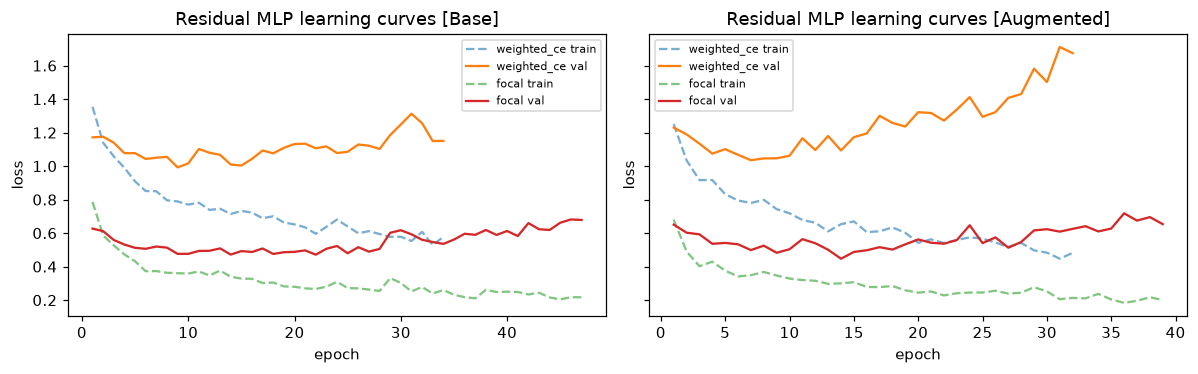

,feature_set,loss,val macro-F1,best epoch,best val loss
0,Base,weighted_ce,0.4472,9,0.9924
1,Base,focal,0.4398,22,0.4711
2,Augmented,weighted_ce,0.4465,7,1.0353
3,Augmented,focal,0.4506,14,0.4470


In [10]:
MODEL_SPECS["mlp"] = {"name": "Deep Tabular MLP", "family": "Neural Network (M4)", "module": "M4",
                      "make": lambda: TabularResNetClassifier(epochs=MLP_EPOCHS, patience=MLP_PATIENCE,
                                                              random_state=RANDOM_STATE)}

mlp_rows, mlp_curves = [], {}
for fs in FEATURE_SETS:
    best = None
    for loss in ["weighted_ce", "focal"]:
        net = MODEL_SPECS["mlp"]["make"]().set_params(loss=loss)
        net.fit(X[(fs, "train")], y["train"], eval_set=(X[(fs, "val")], y["val"]))
        score = macro_f1(y["val"], net.predict_proba(X[(fs, "val")]))
        mlp_rows.append({"feature_set": fs, "loss": loss, "val macro-F1": round(score, 4),
                         "best epoch": net.best_epoch_, "best val loss": round(net.best_val_loss_, 4)})
        mlp_curves[(fs, loss)] = pd.DataFrame(net.history_)
        if best is None or score > best[0]:
            best = (score, loss)
    BEST_EST[("mlp", fs)] = MODEL_SPECS["mlp"]["make"]().set_params(loss=best[1])
    TUNING[("mlp", fs)] = {"params": {"loss": best[1]}, "search_cv_macro_f1": np.nan}
    log(f"MLP [{fs}]: using loss={best[1]}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    for loss in ["weighted_ce", "focal"]:
        h = mlp_curves[(fs, loss)]
        ax.plot(h["epoch"], h["train_loss"], ls="--", alpha=0.6, label=f"{loss} train")
        ax.plot(h["epoch"], h["val_loss"], label=f"{loss} val")
    ax.set(title=f"Residual MLP learning curves [{fs}]", xlabel="epoch", ylabel="loss")
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "mlp_learning_curves.png"), bbox_inches="tight")
plt.show()
pd.DataFrame(mlp_rows)

## 4. Two-stage benchmarking of the advanced models
Every advanced model × {Base, Augmented} goes through `run_model`: 5-fold OOF on train (CV Macro F1), refit on all of train, scored on test. The fold assignment is identical for every model and both feature sets, so differences are paired.

In [11]:
M4_KEYS = TREE_KEYS + ["mlp"]
for key in M4_KEYS:
    for fs in FEATURE_SETS:
        run_model(key, fs, BEST_EST[(key, fs)])

[13:40:15] Random Forest              [Base     ]  CV macro-F1 0.572 ± 0.053 | test macro-F1 0.536  AUC 0.957  logloss 0.173  (13s)


[13:40:27] Random Forest              [Augmented]  CV macro-F1 0.539 ± 0.065 | test macro-F1 0.553  AUC 0.954  logloss 0.183  (12s)


[13:40:34] Extra Trees                [Base     ]  CV macro-F1 0.532 ± 0.038 | test macro-F1 0.444  AUC 0.948  logloss 0.252  (7s)


[13:40:41] Extra Trees                [Augmented]  CV macro-F1 0.526 ± 0.059 | test macro-F1 0.530  AUC 0.953  logloss 0.168  (7s)


[13:40:50] LightGBM                   [Base     ]  CV macro-F1 0.540 ± 0.075 | test macro-F1 0.569  AUC 0.953  logloss 0.167  (9s)


[13:40:54] LightGBM                   [Augmented]  CV macro-F1 0.541 ± 0.043 | test macro-F1 0.576  AUC 0.955  logloss 0.166  (4s)


... (2 outputs left out)

[13:41:28] CatBoost                   [Base     ]  CV macro-F1 0.556 ± 0.085 | test macro-F1 0.561  AUC 0.960  logloss 0.168  (18s)


[13:42:45] CatBoost                   [Augmented]  CV macro-F1 0.510 ± 0.052 | test macro-F1 0.602  AUC 0.957  logloss 0.161  (77s)


[13:43:19] Deep Tabular MLP           [Base     ]  CV macro-F1 0.418 ± 0.046 | test macro-F1 0.467  AUC 0.926  logloss 0.448  (34s)


[13:43:54] Deep Tabular MLP           [Augmented]  CV macro-F1 0.403 ± 0.069 | test macro-F1 0.458  AUC 0.943  logloss 0.486  (35s)


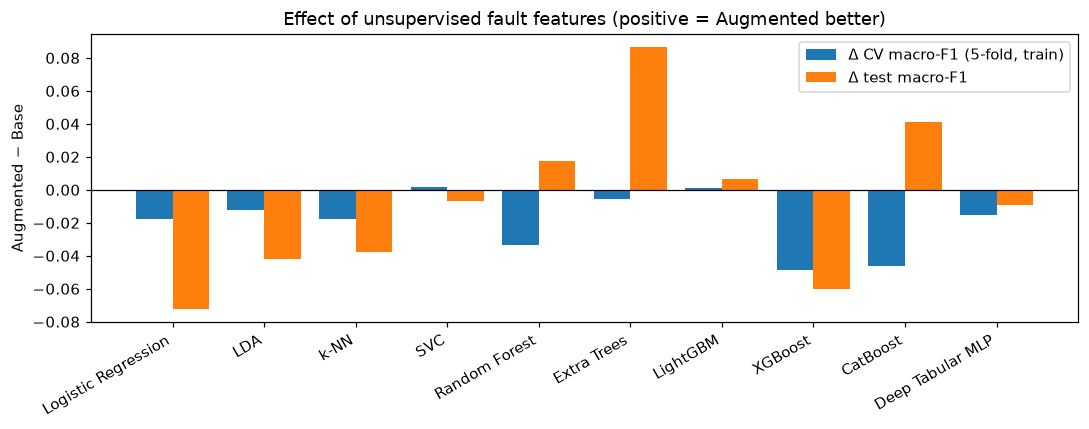

,Δ cv_macro_f1,Δ test_macro_f1,Δ test_roc_auc,Δ test_log_loss
model,,,,
Logistic Regression,-0.0180,-0.0724,-0.0129,0.0342
LDA,-0.0120,-0.0422,-0.0002,0.0376
k-NN,-0.0176,-0.0375,-0.0305,0.1024
SVC,0.0015,-0.0070,-0.0040,0.0125
Random Forest,-0.0332,0.0172,-0.0034,0.0105
Extra Trees,-0.0056,0.0865,0.0055,-0.0844
LightGBM,0.0012,0.0068,0.0018,-0.0010
XGBoost,-0.0489,-0.0601,0.0013,-0.0019
CatBoost,-0.0460,0.0414,-0.0032,-0.0072


In [12]:
def results_table(keys):
    rows = []
    for key in keys:
        for fs in FEATURE_SETS:
            r = RESULTS[(key, fs)]
            rows.append({"model": MODEL_SPECS[key]["name"], "feature_set": fs,
                         "cv_macro_f1": r["cv_scores"].mean(), "cv_std": r["cv_scores"].std(),
                         "test_macro_f1": r["macro_f1"], "test_weighted_f1": r["weighted_f1"],
                         "test_roc_auc": r["roc_auc"], "test_log_loss": r["log_loss"]})
    return pd.DataFrame(rows)


ALL_SINGLE_KEYS = M3_KEYS + M4_KEYS
bench = results_table(ALL_SINGLE_KEYS)
delta = (bench.pivot(index="model", columns="feature_set", values=["cv_macro_f1", "test_macro_f1", "test_roc_auc", "test_log_loss"])
         .pipe(lambda d: pd.DataFrame({m: d[(m, "Augmented")] - d[(m, "Base")] for m in ["cv_macro_f1", "test_macro_f1", "test_roc_auc", "test_log_loss"]}))
         .add_prefix("Δ ").reindex([MODEL_SPECS[k]["name"] for k in ALL_SINGLE_KEYS]))

fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(delta))
ax.bar(xpos - 0.2, delta["Δ cv_macro_f1"], 0.4, label="Δ CV macro-F1 (5-fold, train)")
ax.bar(xpos + 0.2, delta["Δ test_macro_f1"], 0.4, label="Δ test macro-F1")
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(xpos, delta.index, rotation=30, ha="right")
ax.set(ylabel="Augmented − Base", title="Effect of unsupervised fault features (positive = Augmented better)")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "two_stage_deltas.png"), bbox_inches="tight")
plt.show()
delta.round(4)

In [13]:
# Save the tuned Augmented models (spec deliverables) + the extra boosters
SAVE_AS = {"lgbm": "best_lightgbm_aug.joblib", "xgb": "best_xgboost_aug.joblib", "rf": "best_rf_aug.joblib",
           "cat": "best_catboost_aug.joblib", "et": "best_extratrees_aug.joblib"}
for key, fname in SAVE_AS.items():
    joblib.dump(RESULTS[(key, "Augmented")]["model"], os.path.join(ARTIFACTS_DIR, fname))
RESULTS[("mlp", "Augmented")]["model"].save_pt(os.path.join(ARTIFACTS_DIR, "best_mlp_aug.pt"), feature_names=AUG_FEATURES)

# round-trip check of the .pt export
_reloaded = TabularResNetClassifier.load_pt(os.path.join(ARTIFACTS_DIR, "best_mlp_aug.pt"))
assert np.allclose(_reloaded.predict_proba(X[("Augmented", "test")]), RESULTS[("mlp", "Augmented")]["test_proba"], atol=1e-5)
print("Saved:", sorted(os.listdir(ARTIFACTS_DIR)))

Saved: ['best_catboost_aug.joblib', 'best_extratrees_aug.joblib', 'best_lightgbm_aug.joblib', 'best_mlp_aug.pt', 'best_rf_aug.joblib', 'best_xgboost_aug.joblib', 'end_to_end_pipeline.joblib', 'm3_fallback', 'run_log.txt', 'run_summary.json', 'stacking_meta_learner.joblib']


## 5. Model integration: soft voting & Level-1 stacking
**Weighted soft voting** — average the class-probability vectors of LightGBM, Random Forest, SVC and the MLP (Augmented), with weights ∝ each model's 5-fold OOF Macro F1. Its CV score is computed by applying the same averaging to the OOF matrices.

**Stacking meta-learner** — Level-0 features are the OOF probabilities of Module 3's Logistic / SVC / *k*-NN / LDA and Module 4's RF / LightGBM / MLP (7 models × 4 classes = 28 columns). Because every Level-0 column for a training row was produced by a model that never saw that row, the meta-learner can be trained on them without leakage. Test-time Level-0 features come from the same models refit on all of train.
Two meta-learners are compared by 5-fold CV on the OOF matrix: L2 logistic regression (`C` tuned) and a shallow LightGBM (depth 2). The better one is refit and scored on test.

In [14]:
# Level-0 probability features: Module 3's delivered OOF/test probabilities (audited in 1b-(i)) + Module 4's
m3_src = M3_DELIVERED if M3_AVAILABLE else {k: RESULTS[(k, "Augmented")] for k in STACK_M3_KEYS}
level0 = {k: (m3_src[k]["oof"], m3_src[k]["test_proba"]) for k in STACK_M3_KEYS}
level0.update({k: (RESULTS[(k, "Augmented")]["oof"], RESULTS[(k, "Augmented")]["test_proba"]) for k in STACK_M4_KEYS})

# Fitted Level-0 models for inference: Module 3's own model where it loads, else the Module 4 re-run (flagged)
LEVEL0_MODELS, LEVEL0_MODEL_SOURCE = {}, {}
for k in STACK_M3_KEYS:
    if M3_AVAILABLE and M3_DELIVERED[k]["model"] is not None:
        LEVEL0_MODELS[k], LEVEL0_MODEL_SOURCE[k] = M3_DELIVERED[k]["model"], "Module 3 delivered model"
    else:
        LEVEL0_MODELS[k] = RESULTS[(k, "Augmented")]["model"]
        LEVEL0_MODEL_SOURCE[k] = ("Module 4 re-run (substitute: Module 3's model could not be loaded; the meta-learner "
                                  "was trained on Module 3's OOF for this slot)") if M3_AVAILABLE else "Module 4 re-run"
for k in STACK_M4_KEYS:
    LEVEL0_MODELS[k], LEVEL0_MODEL_SOURCE[k] = RESULTS[(k, "Augmented")]["model"], "Module 4"
print("Module 3 Level-0 source:", M3_SOURCE)
display(pd.Series(LEVEL0_MODEL_SOURCE, name="inference model source").to_frame())

LEVEL0_ORDER = STACK_M3_KEYS + STACK_M4_KEYS
STACK_COLS = [f"{k}_prob_{c}" for k in LEVEL0_ORDER for c in CLASSES]
Z_train = pd.DataFrame(np.hstack([level0[k][0] for k in LEVEL0_ORDER]), columns=STACK_COLS)
Z_test = pd.DataFrame(np.hstack([level0[k][1] for k in LEVEL0_ORDER]), columns=STACK_COLS)
print("Stacking matrix:", Z_train.shape, Z_test.shape)

Module 3 Level-0 source: Module 3 delivered (module3/artifacts/oof_predictions)


,inference model source
lr,Module 3 delivered model
svm,Module 3 delivered model
knn,Module 4 re-run (substitute: Module 3's model could not be loaded; the meta-learner was trained on Module 3's OOF for this slot)
lda,Module 3 delivered model
rf,Module 4
lgbm,Module 4
mlp,Module 4


Stacking matrix: (3105, 28) (666, 28)


In [15]:
# ---- Weighted soft voting ----
vote_w = np.array([RESULTS[(k, "Augmented")]["cv_scores"].mean() for k in VOTING_KEYS])
vote_w = vote_w / vote_w.sum()
vote_oof = sum(w * RESULTS[(k, "Augmented")]["oof"] for w, k in zip(vote_w, VOTING_KEYS))
vote_test = sum(w * RESULTS[(k, "Augmented")]["test_proba"] for w, k in zip(vote_w, VOTING_KEYS))
vote_cv = np.array([macro_f1(y["train"][va], vote_oof[va]) for _, va in CV5.split(X[("Augmented", "train")], y["train"])])
print("Voting weights:", dict(zip(VOTING_KEYS, vote_w.round(3))))

# ---- Stacking meta-learner ----
meta_candidates = {
    "Logistic Regression (L2)": GridSearchCV(LogisticRegression(class_weight="balanced", max_iter=5000),
                                             {"C": [0.01, 0.1, 1.0, 10.0]}, scoring="f1_macro", cv=CV_SEARCH),
    "Shallow LightGBM": lgb.LGBMClassifier(objective="multiclass", class_weight="balanced", n_estimators=150,
                                           learning_rate=0.05, max_depth=2, num_leaves=4, min_child_samples=5,
                                           verbosity=-1, random_state=RANDOM_STATE),
}
meta_rows = {}
for name, meta in meta_candidates.items():
    oof_meta = cross_val_predict(meta, Z_train, y["train"], cv=CV5, method="predict_proba")
    scores = np.array([macro_f1(y["train"][va], oof_meta[va]) for _, va in CV5.split(Z_train, y["train"])])
    meta_rows[name] = scores
    print(f"meta-learner {name:<26s} CV macro-F1 {scores.mean():.3f} ± {scores.std():.3f}")

META_NAME = max(meta_rows, key=lambda n: meta_rows[n].mean())
meta_model = clone(meta_candidates[META_NAME]).fit(Z_train, y["train"])
stack_test = meta_model.predict_proba(Z_test)
print(f"Selected meta-learner: {META_NAME}")

Voting weights: {'lgbm': np.float64(0.282), 'rf': np.float64(0.281), 'svm': np.float64(0.228), 'mlp': np.float64(0.21)}


meta-learner Logistic Regression (L2)   CV macro-F1 0.503 ± 0.058


meta-learner Shallow LightGBM           CV macro-F1 0.522 ± 0.040
Selected meta-learner: Shallow LightGBM


In [16]:
# Latency of the full stack for one event: all Level-0 models + meta-learner
def stack_predict_proba(row_aug):
    feats = [LEVEL0_MODELS[k].predict_proba(row_aug) for k in LEVEL0_ORDER]
    return meta_model.predict_proba(pd.DataFrame(np.hstack(feats), columns=STACK_COLS))

class _Fn:  # tiny adapter so single_row_latency_ms can time a function
    def __init__(self, f): self.predict_proba = f

stack_latency = single_row_latency_ms(_Fn(stack_predict_proba), X[("Augmented", "test")], n=20)
vote_latency = single_row_latency_ms(_Fn(lambda r: sum(w * RESULTS[(k, "Augmented")]["model"].predict_proba(r)
                                                        for w, k in zip(vote_w, VOTING_KEYS))), X[("Augmented", "test")], n=20)

ENSEMBLES = {
    "voting": {"name": "Weighted Soft Voting (LGBM+RF+SVC+MLP)", "family": "Ensemble (M4)", "fs": "Augmented",
               "cv_scores": vote_cv, "test_proba": vote_test, "latency_ms": vote_latency},
    "stack": {"name": f"Stacking Classifier ({META_NAME} meta)", "family": "Ensemble (M4)", "fs": "Augmented",
              "cv_scores": meta_rows[META_NAME], "test_proba": stack_test, "latency_ms": stack_latency},
}
for e in ENSEMBLES.values():
    e.update(evaluate(y["test"], e["test_proba"]))
    print(f"{e['name']:<48s} CV {e['cv_scores'].mean():.3f}  test macro-F1 {e['macro_f1']:.3f}  AUC {e['roc_auc']:.3f}")

# Level-0 models are needed at inference, so they ship inside the artifact (sources recorded per slot)
joblib.dump({"meta_learner": meta_model, "meta_learner_name": META_NAME, "level0_order": LEVEL0_ORDER,
             "stack_columns": STACK_COLS, "feature_cols": AUG_FEATURES, "classes": CLASSES,
             "m3_source": M3_SOURCE, "level0_model_source": LEVEL0_MODEL_SOURCE,
             "level0_models": LEVEL0_MODELS},
            os.path.join(ARTIFACTS_DIR, "stacking_meta_learner.joblib"))
print("saved stacking_meta_learner.joblib")

Weighted Soft Voting (LGBM+RF+SVC+MLP)           CV 0.532  test macro-F1 0.591  AUC 0.963
Stacking Classifier (Shallow LightGBM meta)      CV 0.522  test macro-F1 0.506  AUC 0.948


saved stacking_meta_learner.joblib


## 6. Master comparative leaderboard & statistical significance
### 6a. Leaderboard (Module 3 families + Module 4 models + ensembles)
Test metrics are on the 666-event held-out test set; **CV Macro F1** is the 5-fold mean ± std on train (more stable — see the note at the top). Latency is the median wall-clock time of one `predict_proba` call on a single pre-featurised row (for ensembles: every member + meta-learner; blank where the model could not be loaded).

Module 3 appears twice: *"Module 3 delivered"* rows are Module 3's own tuned Augmented models, scored from their delivered OOF/test probabilities; *"re-run in M4"* rows are the same families tuned and refit under Module 4's protocol on both feature sets (these drive the Base-vs-Augmented tests in §6b).

In [17]:
lb_rows, PROBA_BY_NAME = [], {}


def add_row(family, name, fs, r):
    lb_rows.append({"Model Family": family, "Specific Model": name, "Feature Set": fs,
                    "CV Macro F1": r["cv_scores"].mean(), "CV Std": r["cv_scores"].std(),
                    "Macro F1": r["macro_f1"], "Weighted F1": r["weighted_f1"], "Multi-Class ROC-AUC": r["roc_auc"],
                    "Log Loss": r["log_loss"], "Latency (ms)": r["latency_ms"]})
    PROBA_BY_NAME[(name, fs)] = r["test_proba"]


for key in M3_KEYS:
    if M3_AVAILABLE:
        add_row(MODEL_SPECS[key]["family"], f"{M3_DELIVERED[key]['label']} — Module 3 delivered", "Augmented", M3_DELIVERED[key])
    for fs in FEATURE_SETS:
        add_row(MODEL_SPECS[key]["family"], f"{config_label(key, fs)} — re-run in M4", fs, RESULTS[(key, fs)])
for key in M4_KEYS:
    for fs in FEATURE_SETS:
        add_row(MODEL_SPECS[key]["family"], MODEL_SPECS[key]["name"], fs, RESULTS[(key, fs)])
for e in ENSEMBLES.values():
    add_row(e["family"], e["name"], e["fs"], e)
leaderboard = pd.DataFrame(lb_rows)
leaderboard.to_csv(os.path.join(REPORTS_DIR, "final_comparative_leaderboard.csv"), index=False)
leaderboard.sort_values("CV Macro F1", ascending=False).reset_index(drop=True).round(4)

,Model Family,Specific Model,Feature Set,CV Macro F1,CV Std,Macro F1,Weighted F1,Multi-Class ROC-AUC,Log Loss,Latency (ms)
0,Tree Ensemble (M4),Random Forest,Base,0.5725,0.0528,0.5359,0.9442,0.9569,0.1727,32.1105
1,Gradient Boost (M4),CatBoost,Base,0.5564,0.0848,0.5606,0.9447,0.9598,0.1679,2.3354
2,Gradient Boost (M4),LightGBM,Augmented,0.5414,0.0426,0.5760,0.9461,0.9548,0.1659,1.4116
3,Gradient Boost (M4),LightGBM,Base,0.5402,0.0748,0.5692,0.9502,0.9530,0.1668,1.5770
4,Tree Ensemble (M4),Random Forest,Augmented,0.5392,0.0653,0.5531,0.9447,0.9535,0.1831,30.8062
5,Ensemble (M4),Weighted Soft Voting (LGBM+RF+SVC+MLP),Augmented,0.5320,0.0505,0.5911,0.9532,0.9631,0.2047,41.4572
6,Tree Ensemble (M4),Extra Trees,Base,0.5320,0.0384,0.4440,0.9304,0.9476,0.2525,32.1981
7,Gradient Boost (M4),XGBoost,Base,0.5303,0.0708,0.5797,0.9414,0.9528,0.2260,3.4482
8,Tree Ensemble (M4),Extra Trees,Augmented,0.5263,0.0589,0.5304,0.9422,0.9531,0.1681,33.4678
9,Ensemble (M4),Stacking Classifier (Shallow LightGBM meta),Augmented,0.5220,0.0402,0.5060,0.9437,0.9478,0.1954,56.8173


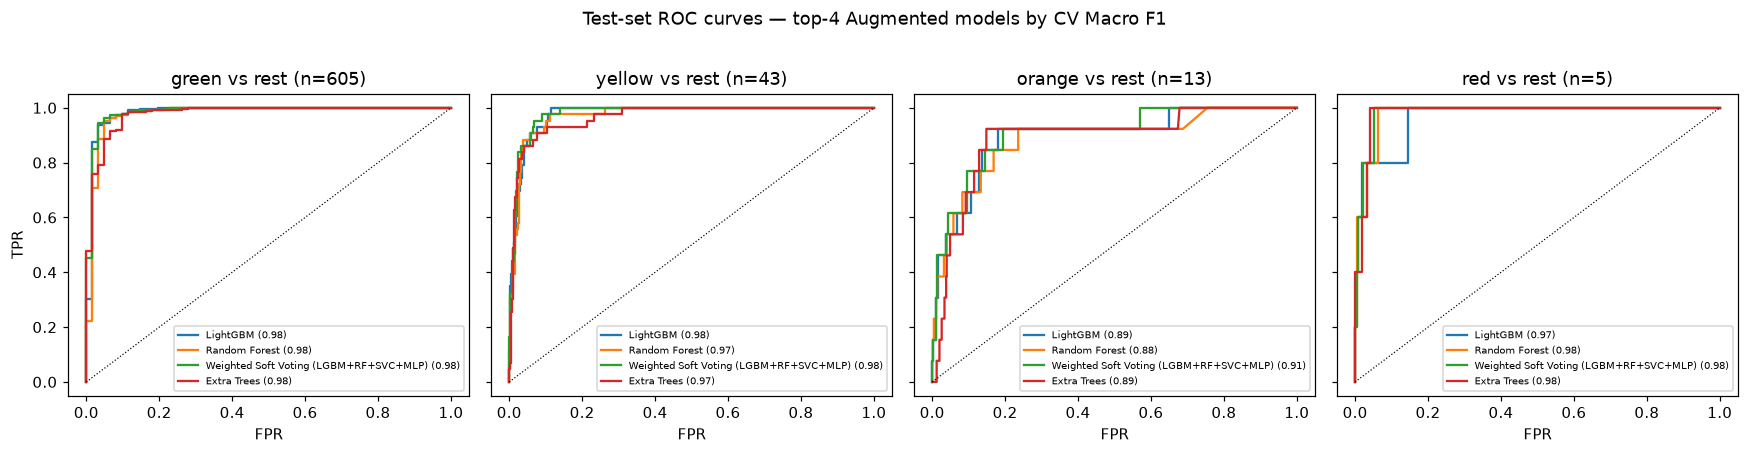

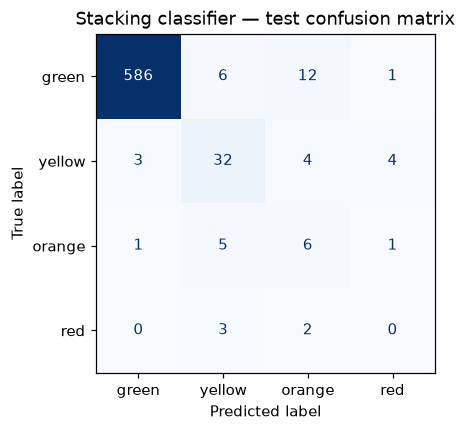

              precision    recall  f1-score   support

       green       0.99      0.97      0.98       605
      yellow       0.70      0.74      0.72        43
      orange       0.25      0.46      0.32        13
         red       0.00      0.00      0.00         5

    accuracy                           0.94       666
   macro avg       0.48      0.54      0.51       666
weighted avg       0.95      0.94      0.94       666



In [18]:
# ROC overlays (one-vs-rest, per alert class) for the strongest models + confusion matrix of the stacker
top_keys = leaderboard[leaderboard["Feature Set"] == "Augmented"].nlargest(4, "CV Macro F1")["Specific Model"].tolist()
name_to_proba = {name: p for (name, fs), p in PROBA_BY_NAME.items() if fs == "Augmented"}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for j, (ax, cls) in enumerate(zip(axes, CLASSES)):
    for name in top_keys:
        fpr, tpr, _ = roc_curve(y["test"] == j, name_to_proba[name][:, j])
        auc_j = roc_auc_score(y["test"] == j, name_to_proba[name][:, j])
        ax.plot(fpr, tpr, label=f"{name[:44]} ({auc_j:.2f})")
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set(title=f"{cls} vs rest (n={int((y['test'] == j).sum())})", xlabel="FPR")
    ax.legend(fontsize=6.5, loc="lower right")
axes[0].set_ylabel("TPR")
fig.suptitle("Test-set ROC curves — top-4 Augmented models by CV Macro F1", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "roc_overlays_test.png"), bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y["test"], stack_test.argmax(1), labels=LABELS),
                       display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Stacking classifier — test confusion matrix")
fig.savefig(os.path.join(FIG_DIR, "confusion_matrix_stacking.png"), bbox_inches="tight")
plt.show()
print(classification_report(y["test"], stack_test.argmax(1), labels=LABELS, target_names=CLASSES, zero_division=0))

### 6b. Is the Augmented feature set significantly better?
For every model the null hypothesis is *H₀: Macro F1(Augmented) = Macro F1(Base)*.

- **5×2 CV paired *t*-test** (Dietterich, 1998): 5 repetitions of stratified 2-fold CV on train; both feature sets are trained and scored on exactly the same halves. With differences $p_i^{(j)}$ (repetition $i$, fold $j$), $s_i^2 = \sum_j (p_i^{(j)} - \bar p_i)^2$ and
  $t = p_1^{(1)} / \sqrt{\tfrac15 \sum_i s_i^2}$ ~ $t_5$. It is the recommended test when the same data are reused across folds (ordinary paired *t*-tests on CV folds are anti-conservative).
- **Wilcoxon signed-rank** on the same 10 paired differences (non-parametric check).
- **Holm–Bonferroni** correction across the 10 model families, because we test 10 hypotheses at once.

The tests are **two-sided**: a small *p* says the two feature sets differ, not which one is better. The **verdict** column therefore combines significance with direction: *Augmented significantly better* / *Augmented significantly worse* / *no significant difference*. Dietterich's statistic uses only the first fold's difference in its numerator, so its sign can disagree with the mean difference over all 10 folds; when that happens the verdict is *inconclusive*.

Finally the headline comparison from the TODO: **best Augmented model vs best Base model** (each chosen by 5-fold CV Macro F1), on the same 5×2 splits. The TODO's checklist item "p < 0.05 between the best Augmented and best Base model" only counts as passed when Augmented is the **better** side.

In [19]:
FIVE_BY_TWO = {}   # (key, fs) -> (N_5X2_REPS, 2) array of macro-F1 scores; identical splits for every entry


def five_by_two_scores(key, fs):
    if (key, fs) in FIVE_BY_TWO:
        return FIVE_BY_TWO[(key, fs)]
    Xtr, ytr = X[(fs, "train")], y["train"]
    out = np.zeros((N_5X2_REPS, 2))
    for i in range(N_5X2_REPS):
        skf = StratifiedKFold(2, shuffle=True, random_state=RANDOM_STATE + i)
        for j, (a, b) in enumerate(skf.split(Xtr, ytr)):
            m = fit_model(key, clone(BEST_EST[(key, fs)]), Xtr.iloc[a], ytr[a])
            out[i, j] = macro_f1(ytr[b], m.predict_proba(Xtr.iloc[b]))
    FIVE_BY_TWO[(key, fs)] = out
    return out


def paired_5x2_t(scores_a, scores_b):
    d = scores_a - scores_b
    s2 = ((d - d.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    t = d[0, 0] / np.sqrt(s2.mean()) if s2.mean() > 0 else 0.0
    return float(t), float(2 * stats.t.sf(abs(t), df=len(d)))


def wilcoxon_p(scores_a, scores_b):
    d = (scores_a - scores_b).ravel()
    if np.allclose(d, 0):
        return 1.0
    return float(stats.wilcoxon(d, zero_method="zsplit").pvalue)


def verdict(t_stat, mean_delta, p):
    # Two-sided p + direction -> plain-language verdict (Augmented relative to Base)
    if p >= ALPHA:
        return "no significant difference"
    if np.sign(t_stat) != np.sign(mean_delta):
        return "inconclusive (t and mean Δ disagree in sign)"
    return "Augmented significantly better" if mean_delta > 0 else "Augmented significantly worse"


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


t0 = time.perf_counter()
sig_rows = []
for key in ALL_SINGLE_KEYS:
    sa, sb = five_by_two_scores(key, "Augmented"), five_by_two_scores(key, "Base")
    t_stat, p_t = paired_5x2_t(sa, sb)
    sig_rows.append({"model": MODEL_SPECS[key]["name"], "5x2 mean F1 Base": sb.mean(), "5x2 mean F1 Aug": sa.mean(),
                     "Δ (Aug−Base)": sa.mean() - sb.mean(), "t (5x2cv)": t_stat, "p (5x2cv t)": p_t,
                     "p (Wilcoxon)": wilcoxon_p(sa, sb)})
    log(f"5x2 done: {MODEL_SPECS[key]['name']:<26s} Δ={sa.mean() - sb.mean():+.4f}  p={p_t:.4f}  ({time.perf_counter() - t0:.0f}s elapsed)")
sig = pd.DataFrame(sig_rows)
sig["p Holm (5x2cv t)"] = holm(sig["p (5x2cv t)"])
sig["verdict (Holm, α=0.05)"] = [verdict(t, d, p) for t, d, p in zip(sig["t (5x2cv)"], sig["Δ (Aug−Base)"], sig["p Holm (5x2cv t)"])]
log(f"5x2 CV finished in {time.perf_counter() - t0:.0f}s")
sig.round(4)

[13:44:15] 5x2 done: Logistic Regression        Δ=+0.0042  p=0.1739  (11s elapsed)


[13:44:15] 5x2 done: LDA                        Δ=+0.0118  p=0.7241  (12s elapsed)


[13:44:16] 5x2 done: k-NN                       Δ=-0.0110  p=0.4959  (12s elapsed)


[13:44:21] 5x2 done: SVC                        Δ=+0.0137  p=0.6592  (17s elapsed)


[13:44:56] 5x2 done: Random Forest              Δ=+0.0010  p=0.5709  (53s elapsed)


[13:45:16] 5x2 done: Extra Trees                Δ=+0.0247  p=0.1115  (72s elapsed)


... (2 outputs left out)

[13:47:52] 5x2 done: CatBoost                   Δ=-0.0032  p=0.0913  (228s elapsed)


[13:49:02] 5x2 done: Deep Tabular MLP           Δ=-0.0380  p=0.4148  (298s elapsed)


[13:49:02] 5x2 CV finished in 298s


,model,5x2 mean F1 Base,5x2 mean F1 Aug,Δ (Aug−Base),t (5x2cv),p (5x2cv t),p (Wilcoxon),p Holm (5x2cv t),"verdict (Holm, α=0.05)"
0,Logistic Regression,0.4564,0.4606,0.0042,1.5847,0.1739,0.4922,1.0000,no significant difference
1,LDA,0.4698,0.4816,0.0118,0.3735,0.7241,0.1309,1.0000,no significant difference
2,k-NN,0.4928,0.4818,-0.0110,0.7340,0.4959,0.4922,1.0000,no significant difference
3,SVC,0.4308,0.4445,0.0137,0.4684,0.6592,0.0645,1.0000,no significant difference
4,Random Forest,0.5359,0.5369,0.0010,0.6061,0.5709,0.9219,1.0000,no significant difference
5,Extra Trees,0.5043,0.5290,0.0247,1.9298,0.1115,0.0371,1.0000,no significant difference
6,LightGBM,0.5655,0.5305,-0.0350,-1.5214,0.1887,0.0098,1.0000,no significant difference
7,XGBoost,0.5384,0.5078,-0.0306,-0.4027,0.7038,0.0059,1.0000,no significant difference
8,CatBoost,0.5242,0.5210,-0.0032,-2.0867,0.0913,0.9219,0.9128,no significant difference
9,Deep Tabular MLP,0.3922,0.3542,-0.0380,-0.8889,0.4148,0.1602,1.0000,no significant difference


In [20]:
cv_mean = {(k, fs): RESULTS[(k, fs)]["cv_scores"].mean() for k in ALL_SINGLE_KEYS for fs in FEATURE_SETS}
BEST_AUG = max(ALL_SINGLE_KEYS, key=lambda k: cv_mean[(k, "Augmented")])
BEST_BASE = max(ALL_SINGLE_KEYS, key=lambda k: cv_mean[(k, "Base")])
sa, sb = five_by_two_scores(BEST_AUG, "Augmented"), five_by_two_scores(BEST_BASE, "Base")
HEADLINE = {"best_aug": MODEL_SPECS[BEST_AUG]["name"], "best_base": MODEL_SPECS[BEST_BASE]["name"],
            "cv_aug": cv_mean[(BEST_AUG, "Augmented")], "cv_base": cv_mean[(BEST_BASE, "Base")],
            "mean_aug_5x2": sa.mean(), "mean_base_5x2": sb.mean()}
HEADLINE["t"], HEADLINE["p_t"] = paired_5x2_t(sa, sb)
HEADLINE["p_wilcoxon"] = wilcoxon_p(sa, sb)
HEADLINE["delta"] = HEADLINE["mean_aug_5x2"] - HEADLINE["mean_base_5x2"]
HEADLINE["verdict"] = verdict(HEADLINE["t"], HEADLINE["delta"], HEADLINE["p_t"])
HEADLINE["significant_improvement"] = HEADLINE["verdict"] == "Augmented significantly better"
print(f"Best Augmented: {HEADLINE['best_aug']} (CV {HEADLINE['cv_aug']:.3f}) vs "
      f"best Base: {HEADLINE['best_base']} (CV {HEADLINE['cv_base']:.3f})")
print(f"5x2cv t = {HEADLINE['t']:.3f}, p = {HEADLINE['p_t']:.4f} | Wilcoxon p = {HEADLINE['p_wilcoxon']:.4f} | "
      f"mean Δ (Aug−Base) = {HEADLINE['delta']:+.4f} -> {HEADLINE['verdict'].upper()} (α = {ALPHA})")

Best Augmented: LightGBM (CV 0.541) vs best Base: Random Forest (CV 0.572)
5x2cv t = 1.317, p = 0.2451 | Wilcoxon p = 0.4316 | mean Δ (Aug−Base) = -0.0053 -> NO SIGNIFICANT DIFFERENCE (α = 0.05)


In [21]:
def md_table(df, float_fmt="{:.4f}"):
    def f(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "no"
        if isinstance(v, (float, np.floating)):
            return float_fmt.format(v)
        return str(v)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(f(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


lb_md = leaderboard.copy()
lb_md["Feature Set"] = lb_md["Feature Set"].map(lambda s: "**Augmented**" if s == "Augmented" else s)
lb_md["CV Macro F1"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(leaderboard["CV Macro F1"], leaderboard["CV Std"])]
lb_md = lb_md.drop(columns="CV Std")
lb_md["Latency (ms)"] = leaderboard["Latency (ms)"].map(lambda v: f"{v:.2f}")
ranked = leaderboard.sort_values("CV Macro F1", ascending=False).head(5)

report = f'''# Module 4 — Final Comparative Leaderboard

{"> **FAST_MODE run** — reduced searches/epochs; not the reported numbers." if FAST_MODE else ""}
Test set: {len(y["test"])} events ({", ".join(f"{c} {int((y['test'] == i).sum())}" for i, c in enumerate(CLASSES))}).
CV Macro F1 = 5-fold stratified CV on train (mean ± std); all other metrics on the held-out test set.
Feature sets follow Module 3's rule: Base = {len(BASE_FEATURES)} columns, Augmented = {len(AUG_FEATURES)} (Base + {len(M2_COLS)} Module 2 columns).
Module 3 rows: {"*Module 3 delivered* = Module 3's own tuned Augmented models, scored from their delivered OOF/test probabilities on the shared folds; *re-run in M4* = the same families re-tuned under Module 4's protocol on both feature sets (used for the Base-vs-Augmented tests)" if M3_AVAILABLE else "Module 3's outputs were not found, so these are Module 4's re-run of the four Module 3 families (same folds, same features)"}.
Stacking Level-0 source for Module 3 models: {M3_SOURCE}.''' + "".join(
    f"\n> Note ({k}): {M3_DELIVERED[k]['note']}" for k in M3_KEYS if M3_AVAILABLE and M3_DELIVERED[k]["note"]) + f'''

{md_table(lb_md)}

## Top 5 by CV Macro F1
{md_table(ranked[["Specific Model", "Feature Set", "CV Macro F1", "Macro F1", "Multi-Class ROC-AUC"]])}

## Base → Augmented deltas (single models)
{md_table(delta.round(4).reset_index().rename(columns={"index": "model"}))}

## Figures
![Two-stage deltas](figures/two_stage_deltas.png)
![ROC overlays](figures/roc_overlays_test.png)
![Stacking confusion matrix](figures/confusion_matrix_stacking.png)
![MLP learning curves](figures/mlp_learning_curves.png)
'''
with open(os.path.join(REPORTS_DIR, "final_comparative_leaderboard.md"), "w", encoding="utf-8") as fh:
    fh.write(report)

v_col = "verdict (Holm, α=0.05)"
better = sig.loc[sig[v_col] == "Augmented significantly better", "model"].tolist()
worse = sig.loc[sig[v_col] == "Augmented significantly worse", "model"].tolist()
n_red, n_orange = int((y["train"] == 3).sum()), int((y["train"] == 2).sum())
INTERP = (
    f"- Per model (Holm-corrected): Augmented is significantly **better** for {', '.join(better) or 'no model'}, "
    f"significantly **worse** for {', '.join(worse) or 'no model'}, and indistinguishable for the remaining "
    f"{len(sig) - len(better) - len(worse)}.\n"
    + {"Augmented significantly better":
           "- Headline: the best model *with* the unsupervised fault features beats the best model without them.\n",
       "Augmented significantly worse":
           "- Headline: the best model *without* the fault features is significantly better than the best model with "
           "them, i.e. adding the 25 Module 2 columns costs Macro F1 for the strongest learners.\n",
       }.get(HEADLINE["verdict"], "- Headline: the best Base and best Augmented models cannot be told apart at this sample size.\n")
    + f"- Context: with only {n_red} red and {n_orange} orange training events, fold-level Macro F1 is dominated by a "
      "handful of rare events, so these tests have limited power and small differences are within split noise. "
      "A likely reason the fault features do not help high-capacity learners: tree ensembles and boosters can learn "
      "spatial structure directly from latitude/longitude/ECEF coordinates, so the DBSCAN/GMM columns are partly "
      "redundant for them, while 25 extra, partly collinear columns (20 GMM posteriors summing to 1) add variance on "
      "the rare classes. Models that cannot carve space as flexibly (kernel/linear) are where explicit fault features "
      "have the most room to help."
)

sig_report = f'''# Module 4 — Statistical Significance: does unsupervised fault discovery help?

{"> **FAST_MODE run** — fewer 5x2 repetitions; not the reported numbers." if FAST_MODE else ""}
**H₀:** Macro F1(Augmented) = Macro F1(Base). Tests: Dietterich's 5×2 CV paired *t*-test (df = 5) and Wilcoxon signed-rank on
the same {2 * N_5X2_REPS} paired fold scores; Holm–Bonferroni correction across the {len(ALL_SINGLE_KEYS)} model families. α = {ALPHA}.
All fits use the tuned hyper-parameters from the notebook and identical stratified halves of the training set for both feature sets.

## Per-model Base vs Augmented
{md_table(sig)}

## Headline: best Augmented model vs best Base model
| | Best Augmented | Best Base |
|---|---|---|
| Model (chosen by 5-fold CV Macro F1) | {HEADLINE["best_aug"]} | {HEADLINE["best_base"]} |
| 5-fold CV Macro F1 | {HEADLINE["cv_aug"]:.4f} | {HEADLINE["cv_base"]:.4f} |
| 5×2 CV mean Macro F1 | {HEADLINE["mean_aug_5x2"]:.4f} | {HEADLINE["mean_base_5x2"]:.4f} |

5×2cv *t* = {HEADLINE["t"]:.3f}, *p* = {HEADLINE["p_t"]:.4f}; Wilcoxon *p* = {HEADLINE["p_wilcoxon"]:.4f}; mean Δ (Aug − Base) = {HEADLINE["delta"]:+.4f}.
**Result: {HEADLINE["verdict"]} (α = {ALPHA}).** The TODO's checklist item (best Augmented beats best Base at *p* < 0.05) is
**{"met" if HEADLINE["significant_improvement"] else "not met"}**.

## Interpretation
{INTERP}
'''
with open(os.path.join(REPORTS_DIR, "statistical_significance.md"), "w", encoding="utf-8") as fh:
    fh.write(sig_report)
print("Wrote final_comparative_leaderboard.md and statistical_significance.md")

Wrote final_comparative_leaderboard.md and statistical_significance.md


## 7. Interpretability: SHAP feature attribution
`shap.TreeExplainer` (exact TreeSHAP) on the **best gradient booster trained on Augmented features** (LightGBM / XGBoost / CatBoost, chosen by CV Macro F1), explained on the test set. SHAP values are in the model's log-odds (margin) space, one set per alert class.

Outputs: global importance (mean |SHAP| summed over classes), importance by feature group, beeswarm plots for the three non-green classes, and dependence plots for `dist_to_nearest_fault_km` and the two most important `gmm_prob_*` columns.

SHAP model: LightGBM | SHAP array (666, 64, 4)


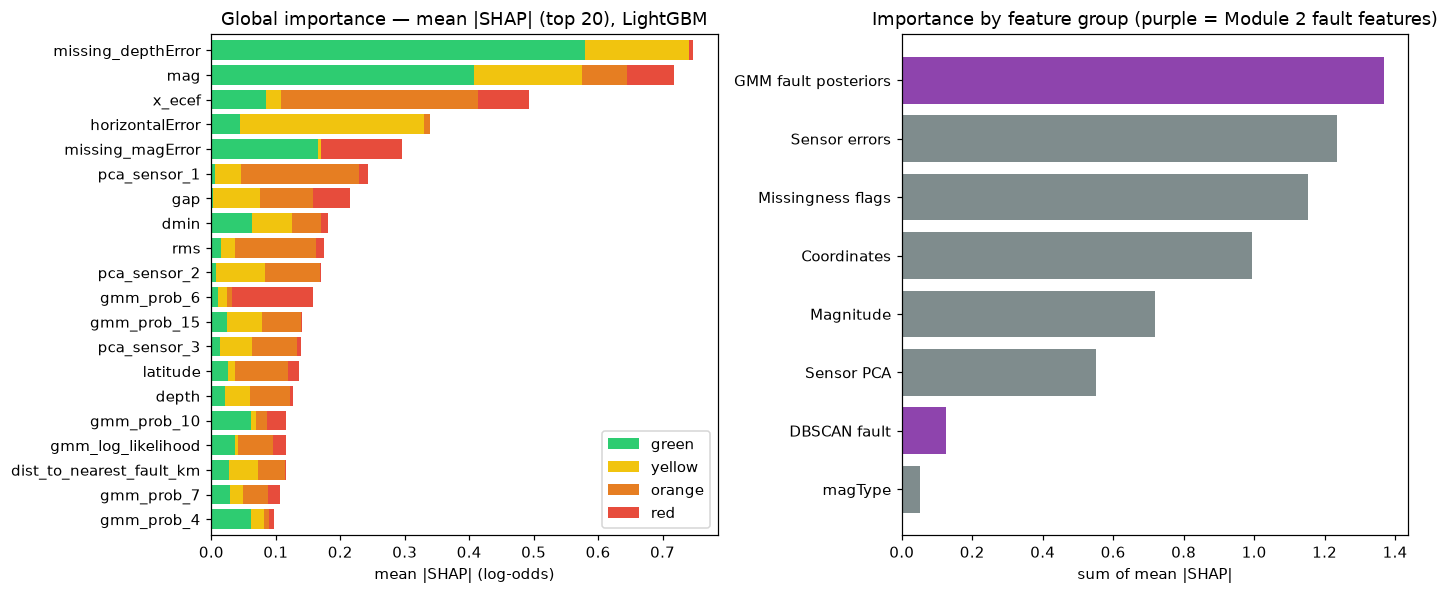

,green,yellow,orange,red,total,rank
missing_depthError,0.5801,0.1603,0.0000,0.0076,0.7479,1
mag,0.4081,0.1663,0.0699,0.0741,0.7184,2
x_ecef,0.0855,0.0221,0.3063,0.0793,0.4932,3
horizontalError,0.0449,0.2852,0.0095,0.0000,0.3395,4
missing_magError,0.1651,0.0056,0.0000,0.1249,0.2955,5
pca_sensor_1,0.0051,0.0405,0.1830,0.0142,0.2428,6
gap,0.0029,0.0725,0.0830,0.0569,0.2153,7
dmin,0.0631,0.0624,0.0448,0.0110,0.1814,8
rms,0.0150,0.0217,0.1259,0.0117,0.1743,9
pca_sensor_2,0.0071,0.0767,0.0852,0.0013,0.1704,10


In [22]:
BOOSTERS = ["lgbm", "xgb", "cat"]
SHAP_KEY = max(BOOSTERS, key=lambda k: cv_mean[(k, "Augmented")])
shap_model = RESULTS[(SHAP_KEY, "Augmented")]["model"]
X_shap = X[("Augmented", "test")]
explainer = shap.TreeExplainer(shap_model)
sv = explainer.shap_values(X_shap)
if isinstance(sv, list):                      # older shap: list of (n, f) per class
    sv = np.stack(sv, axis=-1)
if sv.shape[1] != X_shap.shape[1]:            # some versions return (n, C, f)
    sv = np.transpose(sv, (0, 2, 1))
base_values = np.array(explainer.expected_value).reshape(-1)
assert sv.shape == (len(X_shap), len(AUG_FEATURES), len(CLASSES)), sv.shape
print(f"SHAP model: {MODEL_SPECS[SHAP_KEY]['name']} | SHAP array {sv.shape}")

imp = pd.DataFrame(np.abs(sv).mean(axis=0), index=AUG_FEATURES, columns=CLASSES)
imp["total"] = imp.sum(axis=1)
imp = imp.sort_values("total", ascending=False)
imp["rank"] = np.arange(1, len(imp) + 1)
group_imp = pd.Series({g: imp.loc[cols_g, "total"].sum() for g, cols_g in FEATURE_GROUPS.items()}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
top = imp.head(20)[CLASSES][::-1]
top.plot.barh(stacked=True, color=ALERT_COLORS, ax=axes[0], width=0.8)
axes[0].set(title=f"Global importance — mean |SHAP| (top 20), {MODEL_SPECS[SHAP_KEY]['name']}", xlabel="mean |SHAP| (log-odds)")
colors = ["#8e44ad" if g in ("DBSCAN fault", "GMM fault posteriors") else "#7f8c8d" for g in group_imp.index]
axes[1].barh(group_imp.index, group_imp.values, color=colors)
axes[1].set(title="Importance by feature group (purple = Module 2 fault features)", xlabel="sum of mean |SHAP|")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "shap_global_importance.png"), bbox_inches="tight")
plt.show()
imp.head(15).round(4)

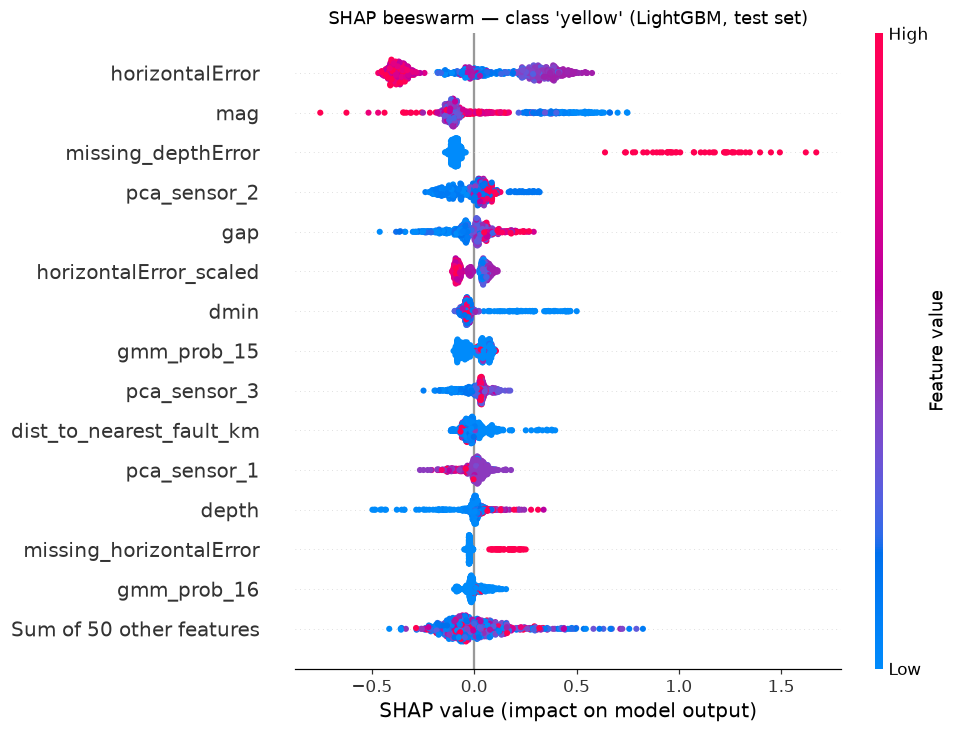

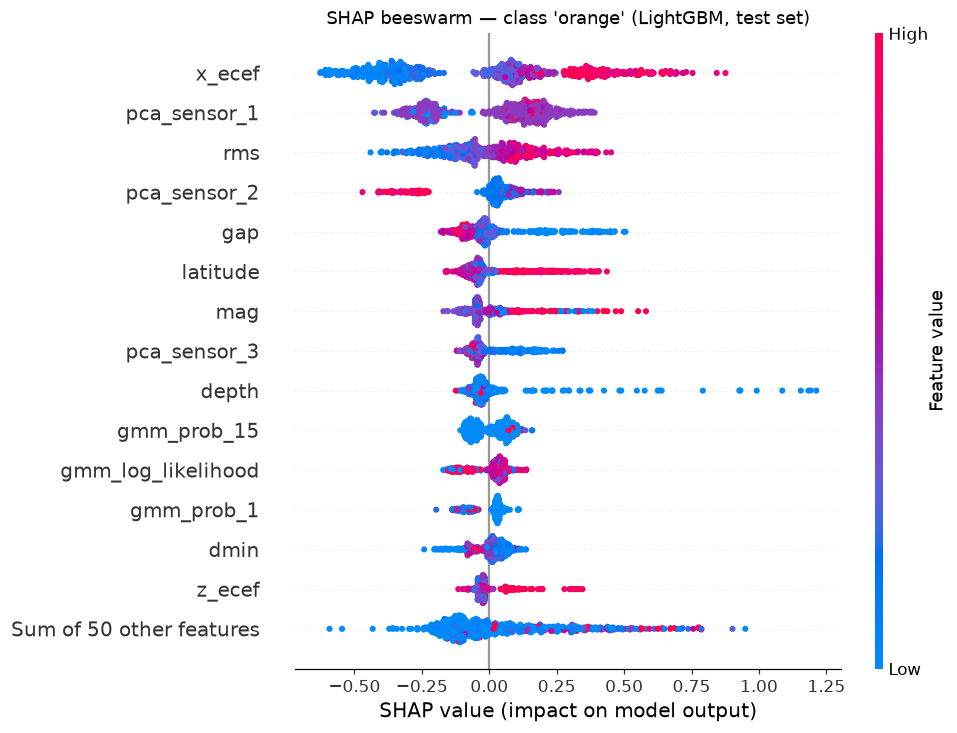

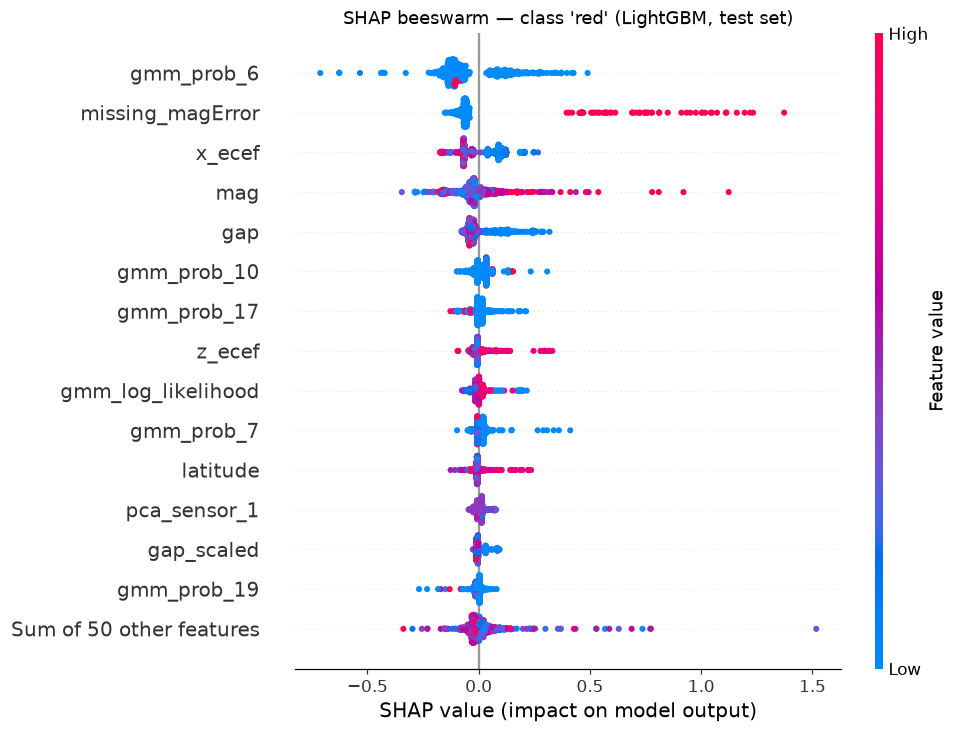

In [23]:
# Beeswarm plots: one per non-green class (the classes a responder cares about)
for j in [1, 2, 3]:
    expl = shap.Explanation(values=sv[:, :, j], base_values=np.full(len(X_shap), base_values[j % len(base_values)]),
                            data=X_shap.to_numpy(), feature_names=AUG_FEATURES)
    plt.figure()
    shap.plots.beeswarm(expl, max_display=15, show=False)
    plt.title(f"SHAP beeswarm — class '{CLASSES[j]}' ({MODEL_SPECS[SHAP_KEY]['name']}, test set)")
    plt.savefig(os.path.join(FIG_DIR, f"shap_beeswarm_{CLASSES[j]}.png"), bbox_inches="tight")
    plt.show()

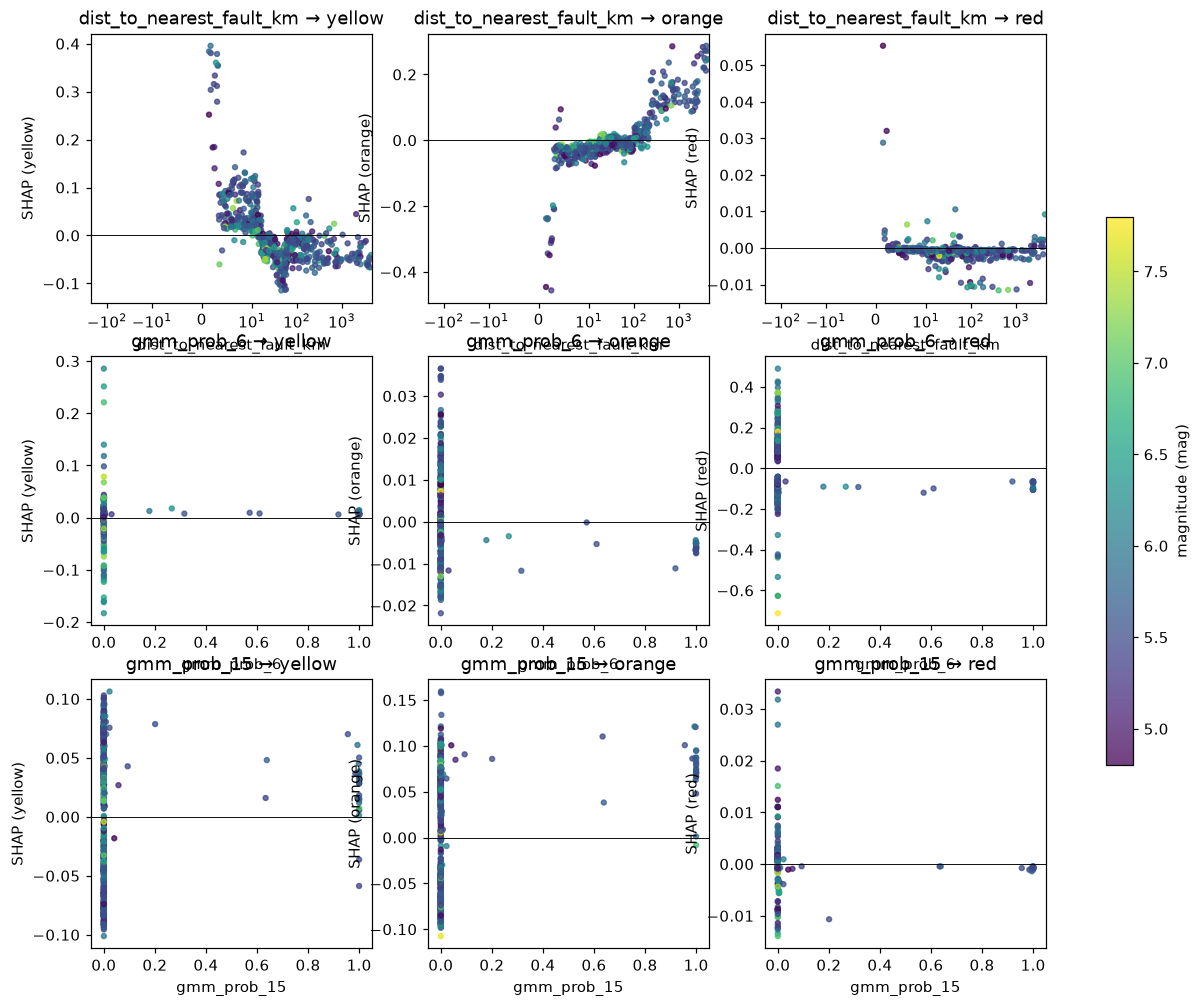

In [24]:
top_gmm = [c for c in imp.index if c.startswith("gmm_prob_")][:2]
DEP_FEATURES = ["dist_to_nearest_fault_km"] + top_gmm
fig, axes = plt.subplots(len(DEP_FEATURES), 3, figsize=(14, 3.6 * len(DEP_FEATURES)), squeeze=False)
for r_i, feat in enumerate(DEP_FEATURES):
    fi = AUG_FEATURES.index(feat)
    for c_i, j in enumerate([1, 2, 3]):
        ax = axes[r_i, c_i]
        sc = ax.scatter(X_shap[feat], sv[:, fi, j], c=X_shap["mag"], cmap="viridis", s=10, alpha=0.75)
        ax.axhline(0, c="k", lw=0.6)
        ax.set(xlabel=feat, ylabel=f"SHAP ({CLASSES[j]})", title=f"{feat} → {CLASSES[j]}")
        if feat == "dist_to_nearest_fault_km":
            ax.set_xscale("symlog", linthresh=10)
fig.colorbar(sc, ax=axes, label="magnitude (mag)", shrink=0.6)
fig.savefig(os.path.join(FIG_DIR, "shap_dependence_fault_features.png"), bbox_inches="tight")
plt.show()

In [25]:
# Data-driven insight summary (numbers, not hand-written claims, so it stays true on re-runs)
high = sv[:, :, 2] + sv[:, :, 3]       # combined push towards orange/red
def direction(feat):
    v = X_shap[feat]
    if v.nunique() < 2:                   # e.g. no background-noise events in the test set
        return np.nan
    return stats.spearmanr(v, high[:, AUG_FEATURES.index(feat)]).correlation

# dbscan_cluster / gmm_cluster are nominal IDs: a rank correlation with them is meaningless, so they are skipped here
fault_feats = ["is_background_noise", "dist_to_nearest_fault_km", "gmm_log_likelihood"] + top_gmm
insight_rows = [{"feature": f, "rank (of %d)" % len(AUG_FEATURES): int(imp.loc[f, "rank"]),
                 "mean |SHAP| total": imp.loc[f, "total"],
                 "Spearman(value, SHAP orange+red)": direction(f)} for f in ["mag", "depth"] + fault_feats]
insights = pd.DataFrame(insight_rows)
m2_share = group_imp[["DBSCAN fault", "GMM fault posteriors"]].sum() / group_imp.sum()
pca_share = group_imp["Sensor PCA"] / group_imp.sum()
top5 = imp.index[:5].tolist()
print(f"Top-5 features: {top5}")
print(f"Share of total |SHAP| from Module 2 fault features: {m2_share:.1%}; from sensor PCA: {pca_share:.1%}")
insights.round(4)

Top-5 features: ['missing_depthError', 'mag', 'x_ecef', 'horizontalError', 'missing_magError']
Share of total |SHAP| from Module 2 fault features: 24.1%; from sensor PCA: 8.9%


C:\Users\jainr\AppData\Local\Temp\ipykernel_8156\91403043.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return stats.spearmanr(v, high[:, AUG_FEATURES.index(feat)]).correlation


,feature,rank (of 64),mean |SHAP| total,"Spearman(value, SHAP orange+red)"
0,mag,2,0.7184,0.4130
1,depth,15,0.1259,-0.2648
2,is_background_noise,63,0.0000,NaN
3,dist_to_nearest_fault_km,18,0.1161,0.7807
4,gmm_log_likelihood,17,0.1162,-0.1237
5,gmm_prob_6,11,0.1576,-0.6579
6,gmm_prob_15,12,0.1412,0.6736


In [26]:
def rho_text(r):
    if not np.isfinite(r):
        return "constant on the test set, so no direction can be estimated"
    if abs(r) < 0.1:
        return "no clear monotone direction"
    return ("higher values push towards orange/red" if r > 0 else "higher values push away from orange/red")

shap_report = f'''# Module 4 — SHAP Explainability Report

Model explained: **{MODEL_SPECS[SHAP_KEY]["name"]} (Augmented)** — the best gradient booster by 5-fold CV Macro F1
({cv_mean[(SHAP_KEY, "Augmented")]:.4f}). Explainer: `shap.TreeExplainer` (exact TreeSHAP), {len(X_shap)} test events,
values in log-odds space per class.

## Global importance
Top-5 features: {", ".join(f"`{f}`" for f in top5)}.

{md_table(imp.head(15).reset_index().rename(columns={"index": "feature"})[["feature", "rank", "yellow", "orange", "red", "total"]])}

Share of total mean |SHAP| contributed by the Module 2 fault features (DBSCAN + GMM): **{m2_share:.1%}**; by sensor PCA: **{pca_share:.1%}**.

![Global importance](figures/shap_global_importance.png)

## Fault-feature effects
{md_table(insights)}

''' + "\n".join(f"- `{r['feature']}` — rank {r['rank (of %d)' % len(AUG_FEATURES)]}; {rho_text(r['Spearman(value, SHAP orange+red)'])}."
               for r in insight_rows) + f'''

![Dependence plots](figures/shap_dependence_fault_features.png)

## Beeswarm plots
![yellow](figures/shap_beeswarm_yellow.png)
![orange](figures/shap_beeswarm_orange.png)
![red](figures/shap_beeswarm_red.png)

## Reading the results
- Magnitude is expected to dominate: PAGER alerts are driven by shaking intensity, which scales with `mag`, then by depth
  (deep events shake the surface less) and by *where* the event is (exposed population, building vulnerability) — the
  coordinates and fault/mixture features are the model's only proxies for location.
- `gmm_prob_*` columns act as learned "seismic region" indicators: a high posterior for a component means the event sits
  in that 3D hypocentral cluster, and its SHAP sign tells whether that region tends to produce higher alerts.
- `dist_to_nearest_fault_km` measures how isolated an event is from the dense fault clusters found by DBSCAN; its
  dependence plot shows whether isolated (background) events are systematically lower- or higher-impact.
- SHAP shows association inside the model, not causation; with {int((y["test"] == 3).sum())} red test events, red-class
  attributions rest on very few examples.
'''
with open(os.path.join(REPORTS_DIR, "shap_explainability_report.md"), "w", encoding="utf-8") as fh:
    fh.write(shap_report)
log("Wrote shap_explainability_report.md")

[13:49:10] Wrote shap_explainability_report.md


## 8. End-to-end inference pipeline
`EarthquakeImpactPipeline` ([`src/earthquake_pipeline.py`](src/earthquake_pipeline.py)):

$$\text{Raw Event Dict} \xrightarrow{\text{M1 Preprocessor}} \text{Base Features} \xrightarrow{\text{M2 Clusterers}} \text{Augmented Features} \xrightarrow{\text{M4 Model}} \text{Prediction}$$

It re-uses the *fitted* Module 1 artifacts (median imputer, robust scaler, magType one-hot, sensor PCA) and Module 2 artifacts (DBSCAN core-point index with the nearest-core-point rule, GMM + its scaler) — no refitting.
Missing sensor readings (`nst`, `gap`, …) are allowed: they become `NaN` → missingness flag + training median, exactly as in Module 1.

**Deployed model:** the single Module 4 model with the best 5-fold CV Macro F1 (chosen on train only, never on test) whose measured end-to-end `predict_single` p95 latency, on 50 real raw events, is ≤ 80 ms (20 % headroom under the 100 ms budget). Candidates are timed in CV order and the first that fits is deployed. `DEPLOY_FEATURE_SETS` controls which feature sets it may use: by default both, because §6b shows the fault features do not improve the strongest models; set it to `["Augmented"]` to deploy the best Augmented model instead. Either way the pipeline always runs Modules 1 **and** 2 and returns the fault distance, DBSCAN cluster and GMM component with every prediction. The stacking artifact is saved separately (it is too slow for the budget: every Level-0 model has to run).

Checks below: (1) the pipeline applied to the **raw** USGS rows of the test events reproduces Module 2's `test_augmented.parquet` features and the model's test probabilities; (2) `predict_single` latency < 100 ms; (3) the exported joblib reloads and gives identical outputs.

In [27]:
preprocessor = joblib.load(os.path.join(M1_ARTIFACTS_DIR, "preprocessor.joblib"))
pca_model = joblib.load(os.path.join(M1_ARTIFACTS_DIR, "pca_model.joblib"))
dbscan_model = joblib.load(os.path.join(M2_ARTIFACTS_DIR, "dbscan_model.joblib"))
gmm_model = joblib.load(os.path.join(M2_ARTIFACTS_DIR, "gmm_model.joblib"))

raw = pd.read_parquet(DATA_RAW_PATH)
raw_test = raw.drop_duplicates("event_id").set_index("event_id").loc[aug["test"]["event_id"]].reset_index()
RAW_FIELDS = ["latitude", "longitude", "depth", "mag", "magType", "nst", "gap", "dmin", "rms",
              "horizontalError", "depthError", "magError"]
bench_events = raw_test.head(50)[RAW_FIELDS].to_dict("records")


def make_pipeline_for(key, fs):
    return EarthquakeImpactPipeline(preprocessor, pca_model, dbscan_model, gmm_model, RESULTS[(key, fs)]["model"],
                                    feature_cols=FEATURE_SETS[fs], model_name=f"{MODEL_SPECS[key]['name']} ({fs})")


def end_to_end_latency(pipe, events):
    for e in events[:3]:
        pipe.predict_single(e)                  # warm-up
    lat = np.array([pipe.predict_single(e)["latency_ms"] for e in events])
    return float(np.median(lat)), float(np.percentile(lat, 95))


# Walk down the candidates in CV order; deploy the first whose measured end-to-end p95 leaves 20 % headroom.
# (Model-only timings were not a reliable guide: single-row latency varies a lot with process state.)
DEPLOY_P95_TARGET_MS = 0.8 * LATENCY_BUDGET_MS
cand_rows = sorted(((cv_mean[(k, fs)], k, fs) for k in M4_KEYS for fs in DEPLOY_FEATURE_SETS), reverse=True)
tried = []
for cv, k, fs in cand_rows:
    med, p95 = end_to_end_latency(make_pipeline_for(k, fs), bench_events)
    tried.append({"model": MODEL_SPECS[k]["name"], "feature_set": fs, "cv_macro_f1": cv,
                  "predict_single median (ms)": med, "predict_single p95 (ms)": p95, "meets target": p95 <= DEPLOY_P95_TARGET_MS})
    if p95 <= DEPLOY_P95_TARGET_MS:
        DEPLOY_KEY, DEPLOY_FS = k, fs
        break
else:
    raise RuntimeError("no Module 4 model meets the latency target")
display(pd.DataFrame(tried).round(4))
pipeline = make_pipeline_for(DEPLOY_KEY, DEPLOY_FS)
deploy_model = pipeline.model
log(f"Deployed model: {pipeline.model_name} | CV macro-F1 {cv_mean[(DEPLOY_KEY, DEPLOY_FS)]:.4f} | "
    f"end-to-end p95 {tried[-1]['predict_single p95 (ms)']:.1f} ms (target {DEPLOY_P95_TARGET_MS:.0f} ms)")

# (1) consistency: raw USGS rows of the test events -> pipeline -> must equal Module 2's test_augmented
feats_pipe = pipeline.transform(raw_test)
max_abs_diff = (feats_pipe[AUG_FEATURES].to_numpy(float) - X[("Augmented", "test")].to_numpy(float))
max_abs_diff = np.abs(max_abs_diff).max(axis=0)
worst = pd.Series(max_abs_diff, index=AUG_FEATURES).sort_values(ascending=False)
print("max |pipeline − test_augmented| per feature (worst 5):"); print(worst.head().to_string())
assert worst.max() < 1e-6, "pipeline does not reproduce Module 1/2 features"
assert (feats_pipe["dbscan_cluster"].values == aug["test"]["dbscan_cluster"].values).all()
proba_pipe = pipeline.predict_proba(raw_test)
assert np.allclose(proba_pipe, RESULTS[(DEPLOY_KEY, DEPLOY_FS)]["test_proba"], atol=1e-6)
print("Pipeline reproduces Module 1 + 2 features and the model's test probabilities exactly.")

,model,feature_set,cv_macro_f1,predict_single median (ms),predict_single p95 (ms),meets target
0,Random Forest,Base,0.5725,56.5326,68.7161,True


[13:49:13] Deployed model: Random Forest (Base) | CV macro-F1 0.5725 | end-to-end p95 68.7 ms (target 80 ms)


max |pipeline − test_augmented| per feature (worst 5):
dist_to_nearest_fault_km    9.272583e-13
z_ecef                      9.094947e-13
y_ecef                      9.094947e-13
x_ecef                      9.094947e-13
gmm_log_likelihood          1.776357e-15
Pipeline reproduces Module 1 + 2 features and the model's test probabilities exactly.


In [28]:
sample_event = {
    "latitude": 37.7749, "longitude": -122.4194, "depth": 12.3, "mag": 6.4, "magType": "mw",
    "nst": 42.0, "gap": 35.0, "dmin": 0.15, "rms": 0.22,
    "horizontalError": 0.8, "depthError": 1.2, "magError": 0.05,
}
result = pipeline.predict_single(sample_event)
print("Predicted Alert:", result["predicted_alert"])
print("Class Probabilities:", {k: round(v, 4) for k, v in result["probabilities"].items()})
print("Nearest Fault Distance (km):", round(result["nearest_fault_distance_km"], 1))
print("DBSCAN cluster:", result["dbscan_cluster"], "| background tremor:", result["is_background_noise"],
      "| GMM component:", result["gmm_cluster"])

# (2) latency benchmark on 200 real raw events
events = raw_test.head(200)[[c for c in raw_test.columns if c in sample_event]].to_dict("records")
lat_ms = np.array([pipeline.predict_single(e)["latency_ms"] for e in events])
LATENCY = {"median_ms": float(np.median(lat_ms)), "p95_ms": float(np.percentile(lat_ms, 95)), "max_ms": float(lat_ms.max())}
print(f"predict_single latency over {len(lat_ms)} events: median {LATENCY['median_ms']:.1f} ms, "
      f"p95 {LATENCY['p95_ms']:.1f} ms, max {LATENCY['max_ms']:.1f} ms (budget {LATENCY_BUDGET_MS:.0f} ms)")

Predicted Alert: green
Class Probabilities: {'green': 0.6878, 'yellow': 0.1509, 'orange': 0.129, 'red': 0.0323}
Nearest Fault Distance (km): 49.8
DBSCAN cluster: 6 | background tremor: False | GMM component: 14


predict_single latency over 200 events: median 53.5 ms, p95 71.1 ms, max 110.5 ms (budget 100 ms)


In [29]:
# (3) export + reload round trip
PIPE_PATH = os.path.join(ARTIFACTS_DIR, "end_to_end_pipeline.joblib")
joblib.dump(pipeline, PIPE_PATH)
reloaded = joblib.load(PIPE_PATH)
r2 = reloaded.predict_single(sample_event)
assert r2["predicted_alert"] == result["predicted_alert"]
assert np.allclose(list(r2["probabilities"].values()), list(result["probabilities"].values()))
log(f"Exported {PIPE_PATH} ({os.path.getsize(PIPE_PATH) / 1e6:.1f} MB) and verified reload.")

[13:49:25] Exported ./artifacts\end_to_end_pipeline.joblib (4.0 MB) and verified reload.


### 8b. Interactive predictor
Slide latitude, longitude, magnitude and depth (and pick a magnitude type) to see the predicted PAGER alert, the class probabilities, and where the event falls relative to the discovered faults. Sensor-quality fields are left missing, so the pipeline imputes Module 1's training medians.
*(Widgets need a live kernel; the static preview below the widget shows one example.)*

In [30]:
import ipywidgets as widgets
from IPython.display import display

MAG_TYPES = list(preprocessor["top_mag_types"]) + ["other"]


def show_prediction(latitude, longitude, mag, depth, magType):
    r = pipeline.predict_single({"latitude": latitude, "longitude": longitude, "mag": mag, "depth": depth,
                                 "magType": magType})
    probs = [r["probabilities"][c] for c in CLASSES]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    bars = ax.barh(CLASSES, probs, color=ALERT_COLORS, edgecolor="k")
    for b, p in zip(bars, probs):
        ax.text(min(p + 0.01, 0.9), b.get_y() + b.get_height() / 2, f"{p:.1%}", va="center")
    where = "background tremor" if r["is_background_noise"] else f"fault cluster {r['dbscan_cluster']}"
    ax.set(xlim=(0, 1), xlabel="probability",
           title=f"Predicted alert: {r['predicted_alert'].upper()}  |  {where}, "
                 f"{r['nearest_fault_distance_km']:.0f} km to nearest fault core  |  {r['latency_ms']:.0f} ms")
    ax.invert_yaxis()
    plt.show()


controls = {
    "latitude": widgets.FloatSlider(value=37.77, min=-90, max=90, step=0.1, description="latitude"),
    "longitude": widgets.FloatSlider(value=-122.42, min=-180, max=180, step=0.1, description="longitude"),
    "mag": widgets.FloatSlider(value=6.4, min=4.5, max=9.0, step=0.1, description="magnitude"),
    "depth": widgets.FloatSlider(value=12.3, min=0, max=700, step=1, description="depth (km)"),
    "magType": widgets.Dropdown(options=MAG_TYPES, value=MAG_TYPES[0], description="magType"),
}
out = widgets.interactive_output(show_prediction, controls)
display(widgets.HBox([widgets.VBox(list(controls.values())[:2] + [controls["magType"]]),
                      widgets.VBox(list(controls.values())[2:4])]), out)

Output()

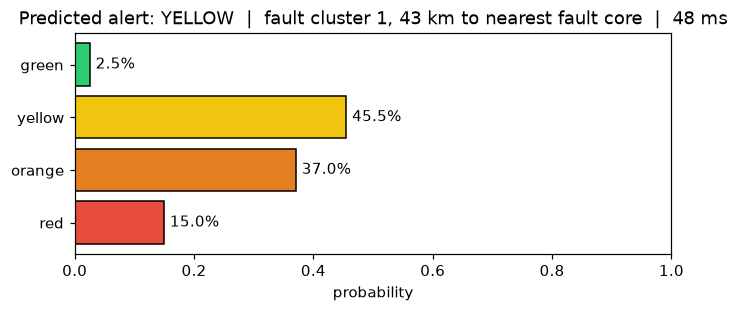

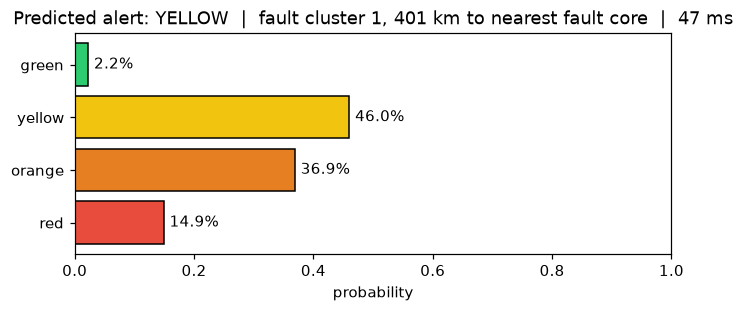

In [31]:
# Static preview (renders without a live kernel): a deep vs a shallow M7.2 near Japan
show_prediction(38.3, 142.4, 7.2, 25.0, MAG_TYPES[0])
show_prediction(38.3, 142.4, 7.2, 450.0, MAG_TYPES[0])

## 9. Validation & sanity checklist (TODO §7)

In [32]:
checks = {
    "All model probabilities sum to 1": all(np.allclose(r["test_proba"].sum(1), 1, atol=1e-5) for r in RESULTS.values()),
    "No target leakage (alert/mmi not in features)": not LEAKY & set(AUG_FEATURES),
    "Pipeline reproduces Module 1/2 test features": bool(worst.max() < 1e-6),
    f"predict_single median latency < {LATENCY_BUDGET_MS:.0f} ms ({LATENCY['median_ms']:.1f} ms)": LATENCY["median_ms"] < LATENCY_BUDGET_MS,
    f"predict_single p95 latency < {LATENCY_BUDGET_MS:.0f} ms ({LATENCY['p95_ms']:.1f} ms)": LATENCY["p95_ms"] < LATENCY_BUDGET_MS,
    (f"Best Augmented significantly BETTER than best Base at p<{ALPHA} "
     f"(p={HEADLINE['p_t']:.3f}, mean Δ={HEADLINE['delta']:+.4f}: {HEADLINE['verdict']})"): bool(HEADLINE["significant_improvement"]),
}
expected = ["best_lightgbm_aug.joblib", "best_xgboost_aug.joblib", "best_rf_aug.joblib", "best_mlp_aug.pt",
            "stacking_meta_learner.joblib", "end_to_end_pipeline.joblib"]
checks["All spec artifacts exist"] = all(os.path.exists(os.path.join(ARTIFACTS_DIR, f)) for f in expected)
reports = ["final_comparative_leaderboard.md", "statistical_significance.md", "shap_explainability_report.md"]
checks["All spec reports exist"] = all(os.path.exists(os.path.join(REPORTS_DIR, f)) for f in reports)
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
print("\nNote: the significance check is a *finding*, not a bug — a FAIL there means the data do not show the "
      "Augmented features significantly improving on Base (see reports/statistical_significance.md).")

PASS All model probabilities sum to 1
PASS No target leakage (alert/mmi not in features)
PASS Pipeline reproduces Module 1/2 test features
PASS predict_single median latency < 100 ms (53.5 ms)
PASS predict_single p95 latency < 100 ms (71.1 ms)
FAIL Best Augmented significantly BETTER than best Base at p<0.05 (p=0.245, mean Δ=-0.0053: no significant difference)
PASS All spec artifacts exist
PASS All spec reports exist

Note: the significance check is a *finding*, not a bug — a FAIL there means the data do not show the Augmented features significantly improving on Base (see reports/statistical_significance.md).


In [33]:
summary = {
    "fast_mode": FAST_MODE, "m3_source": M3_SOURCE, "deployed_model": pipeline.model_name,
    "shap_model": MODEL_SPECS[SHAP_KEY]["name"], "stacking_meta": META_NAME,
    "headline_test": HEADLINE, "latency_ms": LATENCY,
    "best_by_cv": leaderboard.nlargest(3, "CV Macro F1")[["Specific Model", "Feature Set", "CV Macro F1", "Macro F1"]].to_dict("records"),
}
with open(os.path.join(ARTIFACTS_DIR, "run_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

{
  "fast_mode": false,
  "m3_source": "Module 3 delivered (module3/artifacts/oof_predictions)",
  "deployed_model": "Random Forest (Base)",
  "shap_model": "LightGBM",
  "stacking_meta": "Shallow LightGBM",
  "headline_test": {
    "best_aug": "LightGBM",
    "best_base": "Random Forest",
    "cv_aug": 0.5414328050198236,
    "cv_base": 0.5724663905113461,
    "mean_aug_5x2": 0.5305408710265741,
    "mean_base_5x2": 0.5358846224334496,
    "t": 1.3166430678440721,
    "p_t": 0.24507651246695053,
    "p_wilcoxon": 0.431640625,
    "delta": -0.0053437514068754854,
    "verdict": "no significant difference",
    "significant_improvement": false
  },
  "latency_ms": {
    "median_ms": 53.5027000005357,
    "p95_ms": 71.09463499873522,
    "max_ms": 110.53370000445284
  },
  "best_by_cv": [
    {
      "Specific Model": "Random Forest",
      "Feature Set": "Base",
      "CV Macro F1": 0.5724663905113461,
      "Macro F1": 0.5359218581066368
    },
    {
      "Specific Model": "CatBoost",